# 04. Ranking de estaciones y personal de apoyo: ¿qué estaciones y franjas necesitan refuerzo?

**Puntos de la rúbrica:** a (objetivo y unidad de análisis), b (EDA descriptivo, variable objetivo) y c (información adicional).

## Pregunta

> **¿Qué estaciones de la troncal de TransMilenio requieren refuerzo de personal de apoyo para ordenar el ingreso de usuarios, según su demanda por franja horaria?**

**Variable objetivo:** `validaciones` por estación, día y hora (flujo de entrada de personas). **Unidad de análisis:** estación x día x hora. La necesidad de personal no se observa en los datos: se infiere de la demanda con un umbral.

El notebook sigue un hilo: primero se decide **qué días** se analizan; después se define **cómo se mide** la necesidad de refuerzo y de ahí sale **el ranking de estaciones**; con ese ranking se estudia **cuándo** (ventanas de refuerzo), **dónde dentro de la estación** (accesos, minutos dentro de la hora, espacio) y **qué tan estables** son los resultados; luego se miran los **patrones de las estaciones** y, al final, se escogen las **estaciones piloto** (una por punta). El modelo se construye en un notebook aparte (05).

| # | Paso | Qué responde |
|---|---|---|
| 1 | Días que se analizan | ¿Qué días se analizan? La comparación de los días está en el notebook 03. |
| 2 | Del flujo de entradas al ranking | ¿Cómo se mide la necesidad de refuerzo? ¿Qué estaciones y qué horas? ¿Por dónde entra la gente y cómo es la llegada dentro de la hora? **Respuesta descriptiva a la pregunta.** |
| 3 | Patrones de las estaciones | ¿Hay estaciones de mañana (residenciales) y estaciones de tarde (destino)? |
| 4 | Estaciones piloto | ¿Cuál es la estación más crítica de la mañana y de la tarde? ¿Cuántas personas de apoyo y a qué horas? |
| 5 | Personal de apoyo | **¿Cuántas personas y con qué vinculación?** Núcleo fijo y refuerzo variable por estación |

In [1]:
# QUÉ HACE: carga librerías, rutas y estilo de las gráficas, y lee la tabla estación-fecha-hora construida en el notebook 03.
# CÓMO: la tabla trae la fecha, la hora, la estación, el conteo de validaciones, el tipo de día y si el día está completo; de ella se arma el calendario.
# QUÉ MIRAR: 24 fechas, de las cuales 21 son completas (14 hábiles, 3 sábados, 3 domingos y 1 festivo).
import time, warnings, itertools
import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 60)
dask.config.set(scheduler='threads', num_workers=3)
VALIDACIONES = Path('../data/processed/validaciones')
PANEL = Path('../data/processed/panel_estacion_hora.parquet')
RAW = Path('../data/raw/estaciones')
FIGS = Path('../docs/figs'); FIGS.mkdir(parents=True, exist_ok=True)
COL = {'hábil': '#2a78d6', 'sábado': '#eb6834', 'domingo': '#1baf7a', 'festivo': '#e34948'}
FR = {'mañana': '#eda100', 'tarde': '#4a3aa7'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'legend.frameon': False})
DIAS = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']
panel = pd.read_parquet(PANEL)
calendario = panel.groupby('fecha').agg(validaciones=('validaciones', 'sum'), tipo_dia=('tipo_dia', 'first'), completo=('completo', 'first'))
calendario.index = pd.to_datetime(calendario.index); calendario.index.name = 'fecha'
calendario['día'] = [DIAS[d] for d in calendario.index.dayofweek]
calendario['semana'] = (calendario.index - pd.to_timedelta(calendario.index.dayofweek, unit='D')).strftime('%Y-%m-%d')
habiles = sorted(calendario[(calendario['tipo_dia'] == 'hábil') & calendario['completo']].index.strftime('%Y-%m-%d'))
print(f"{len(calendario)} fechas | {int(calendario['completo'].sum())} completas | {len(habiles)} días hábiles: {habiles[0]} a {habiles[-1]}")
calendario.groupby(['tipo_dia', 'completo']).size().unstack(fill_value=0)

24 fechas | 21 completas | 14 días hábiles: 2026-08-03 a 2026-09-18


completo,False,True
tipo_dia,,
domingo,1,3
festivo,0,1
hábil,2,14
sábado,0,3


## 1. Días que se analizan

La comparación de los días (total diario, curva por hora de cada tipo de día, los tres viernes y la variación entre días) está en el notebook 03, sección 2. De ahí sale la decisión que se usa aquí:

- Los días no son iguales: el sábado tiene ~62 % de las validaciones de un día hábil; el domingo y el festivo, ~30 %. El festivo (viernes 7 de agosto) se comporta como un domingo.
- Solo el día hábil tiene dos picos (6 a. m. y 5 p. m.).
- Entre los 14 días hábiles la variación en una misma hora es de 2 a 5 %; con los 21 días sube a 45-49 %.

**Decisión:** se analizan solo los **14 días hábiles** de las tres semanas. Sábado, domingo y festivo son otro régimen y quedan como contexto.


In [2]:
# QUÉ HACE: prepara la curva por hora de cada día (total del sistema) y marca cuáles son días hábiles; la usan las franjas del paso 2.
# CÓMO: suma las validaciones de todas las estaciones por fecha y hora; el tipo de día sale del calendario construido en el notebook 03.
# QUÉ MIRAR: nada que graficar aquí; la comparación de los días está en el notebook 03.
dh = (panel[panel['completo']].groupby(['fecha', 'hora'])['validaciones'].sum().unstack(fill_value=0).reindex(columns=range(24), fill_value=0))
dh.index = pd.to_datetime(dh.index)
tipo_por_dia = calendario.loc[dh.index, 'tipo_dia']; es_habil = (tipo_por_dia == 'hábil').values


## 2. Del flujo de entradas al ranking de estaciones

Se pasa de todo el sistema a cada estación, con los 14 días hábiles. Primero se construye la tabla de estaciones (nombre, demanda por hora, ubicación, área en m² y accesos) y se definen cinco franjas del día:

| Franja | Horas |
|---|---|
| madrugada | 0:00 - 4:59 |
| punta mañana | 5:00 - 8:59 |
| valle | 9:00 - 15:59 |
| punta tarde | 16:00 - 19:59 |
| noche | 20:00 - 23:59 |

In [3]:
# QUÉ HACE: arma la tabla de estaciones (nombre, demanda por hora, ubicación, área en m², vagones y accesos) y el "cubo" estación x fecha x hora de los días hábiles.
# CÓMO: el nombre sale de las validaciones; coordenadas, m² y accesos, de los archivos oficiales de estaciones; el cubo completa con 0 las horas sin validaciones; se marcan las estaciones casi sin uso (< 100 validaciones por día) y las que abren o cierran entre agosto y septiembre.
# QUÉ MIRAR: 154 estaciones; 144 quedan para los rankings (activas y sin cambio de régimen); cuántas tienen m² y coordenadas.
nom = dd.read_parquet(str(VALIDACIONES), columns=['Estacion_Parada'])['Estacion_Parada'].value_counts().compute().reset_index()
nom.columns = ['crudo', 'n']; nom['cod_estacion'] = nom['crudo'].str[1:6]; nom['nombre'] = nom['crudo'].str[8:]
nom = nom.sort_values('n', ascending=False).drop_duplicates('cod_estacion').set_index('cod_estacion')['nombre']

ph = panel[(panel['tipo_dia'] == 'hábil') & panel['completo']]
idx = pd.MultiIndex.from_product([sorted(panel['cod_estacion'].unique()), habiles, range(24)], names=['cod_estacion', 'fecha', 'hora'])
cubo = ph.set_index(['cod_estacion', 'fecha', 'hora'])['validaciones'].reindex(idx, fill_value=0)
por_est_hora = cubo.groupby(['cod_estacion', 'hora']).mean().unstack()                     # validaciones por hora en un día hábil típico
est = pd.DataFrame({'nombre': nom.reindex(por_est_hora.index)})
est['val_dia'] = por_est_hora.sum(axis=1); est['hora_pico'] = por_est_hora.idxmax(axis=1); est['val_hora_pico'] = por_est_hora.max(axis=1)
est['activa'] = est['val_dia'] >= 100

tot = cubo.groupby(['cod_estacion', 'fecha']).sum().unstack()
ago = [f for f in tot.columns if f < '2026-09-01']; sep = [f for f in tot.columns if f >= '2026-09-01']
razon = tot[sep].mean(axis=1) / tot[ago].mean(axis=1).replace(0, np.nan)
cambian = tot.index[(tot[ago].sum(axis=1) == 0) | (tot[sep].sum(axis=1) == 0) | (razon < 0.6) | (razon > 1.67)]
est['cambia_regimen'] = est.index.isin(cambian)

oficial = pd.read_csv(RAW / 'estaciones_troncales.csv', dtype=str, encoding='utf-8-sig').set_index('numero_estacion')
ui = pd.read_csv(RAW / 'estaciones_troncales_ui.csv', dtype=str, encoding='utf-8-sig').set_index('num_est')
est['troncal'] = oficial['troncal_estacion'].reindex(est.index)
est['lat'] = pd.to_numeric(oficial['latitud_estacion'].reindex(est.index)).fillna(pd.to_numeric(ui['latitud'].reindex(est.index)))
est['lon'] = pd.to_numeric(oficial['longitud_estacion'].reindex(est.index)).fillna(pd.to_numeric(ui['longitud'].reindex(est.index)))
est['area_m2'] = pd.to_numeric(ui['area_est'].reindex(est.index)).where(lambda s: s > 50)
est['vagones'] = pd.to_numeric(ui['num_vag'].reindex(est.index)); est['accesos_oficiales'] = pd.to_numeric(ui['num_acc'].reindex(est.index))
FRANJAS = {'madrugada': (0, 4), 'punta mañana': (5, 8), 'valle': (9, 15), 'punta tarde': (16, 19), 'noche': (20, 23)}
for k, (a, z) in FRANJAS.items(): est['vh_' + k] = por_est_hora.loc[est.index, a:z].mean(axis=1)
est = est.sort_values('val_dia', ascending=False)
act = est.index[est['activa'] & ~est['cambia_regimen']]                                   # estaciones de los rankings
print(f"{len(est)} estaciones | {len(act)} para rankings | sin uso: {int((~est['activa']).sum())} | abren o cierran: {list(est.index[est['cambia_regimen'] & est['activa']])}")
print(f"con m²: {int(est.loc[act, 'area_m2'].notna().sum())} de {len(act)} | con coordenadas: {int(est.loc[act, 'lat'].notna().sum())} de {len(act)}")
est.loc[act].head(10)[['nombre', 'troncal', 'val_dia', 'hora_pico', 'val_hora_pico', 'area_m2', 'vagones', 'accesos_oficiales']].round(1)

154 estaciones | 144 para rankings | sin uso: 5 | abren o cierran: ['09123', '09122', '15002', '15003', '15001']
con m²: 117 de 144 | con coordenadas: 133 de 144


,nombre,troncal,val_dia,hora_pico,val_hora_pico,area_m2,vagones,accesos_oficiales
cod_estacion,,,,,,,,
05000,Portal Américas,Americas,71392.6,6,14411.6,NaN,1.0,1.0
02000,Portal Norte - Unicervantes,Autonorte,70314.5,7,9369.2,NaN,1.0,1.0
03000,Portal Suba,Suba,56195.7,6,11407.1,NaN,1.0,1.0
07000,Portal Sur JFK Coop. Financiera,NQS,56063.7,6,11663.7,NaN,1.0,2.0
04000,Cabecera Calle 80,Calle 80,53151.8,7,8619.9,NaN,1.0,1.0
09000,Cabecera Usme,Caracas,51424.4,6,10449.1,NaN,1.0,1.0
06000,Portal El Dorado - C.C. NUESTRO BOGOTA,Calle 26,49292.4,7,6167.1,NaN,1.0,1.0
10000,Portal 20 de Julio,Cr 7-10,41969.4,6,8207.3,NaN,1.0,1.0
02300,Calle 100 - Marketmedios,Autonorte,41609.2,17,7646.9,814.4,3.0,2.0


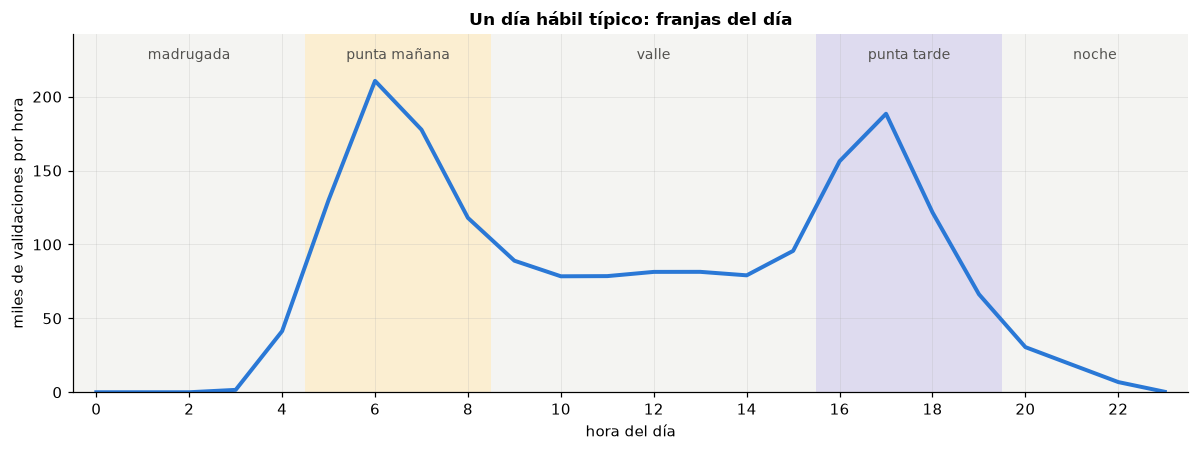

,horas,validaciones por hora (sistema),% de las validaciones del día,estaciones >= 1.000 por hora (promedio de la franja)
madrugada,5.0,8596.2,2.3,1.0
punta mañana,4.0,159096.2,34.4,33.0
valle,7.0,83391.1,31.5,19.0
punta tarde,4.0,133193.9,28.8,46.0
noche,4.0,14094.1,3.0,0.0


In [4]:
# QUÉ HACE: dibuja la curva horaria de un día hábil típico con las cinco franjas, y resume cada franja (demanda por hora y parte del día).
# CÓMO: promedio de los 14 días hábiles del total del sistema; las bandas de color son las franjas; la tabla cuenta también cuántas estaciones superan 1.000 validaciones por hora en promedio en esa franja.
# QUÉ MIRAR: las dos puntas concentran ~63 % de la demanda en 8 horas; el valle es parejo; madrugada y noche son marginales.
curva = dh[es_habil].mean() / 1e3
fig, ax = plt.subplots(figsize=(11, 4.2))
sombra = {'madrugada': '#c3c2b7', 'punta mañana': FR['mañana'], 'valle': '#c3c2b7', 'punta tarde': FR['tarde'], 'noche': '#c3c2b7'}
for k, (a, z) in FRANJAS.items():
    ax.axvspan(a - 0.5, z + 0.5, color=sombra[k], alpha=0.18, lw=0); ax.text((a + z) / 2, curva.max() * 1.07, k, ha='center', fontsize=9, color='#52514e')
ax.plot(range(24), curva, color=COL['hábil'], lw=2.6)
ax.set_xlim(-0.5, 23.5); ax.set_ylim(0, curva.max() * 1.15); ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hora del día'); ax.set_ylabel('miles de validaciones por hora')
ax.set_title('Un día hábil típico: franjas del día'); plt.tight_layout(); plt.savefig(FIGS / '04_franjas_dia_habil.png', bbox_inches='tight'); plt.show()
fr = pd.DataFrame({k: {'horas': z - a + 1, 'validaciones por hora (sistema)': est['vh_' + k].sum(), '% de las validaciones del día': est['vh_' + k].sum() * (z - a + 1) / est['val_dia'].sum() * 100,
                       'estaciones >= 1.000 por hora (promedio de la franja)': int((est.loc[act, 'vh_' + k] >= 1000).sum())} for k, (a, z) in FRANJAS.items()}).T
fr.round(1)

In [5]:
# QUÉ HACE: mide cuántas estaciones reúnen la mitad de las validaciones de un día hábil y lista las 10 más grandes.
# CÓMO: se ordenan las estaciones activas de mayor a menor demanda y se acumula su participación.
# QUÉ MIRAR: pocas estaciones reúnen la mitad de la demanda y casi todas son portales o cabeceras.
e = est.loc[act].copy(); e['% del sistema'] = e['val_dia'] / e['val_dia'].sum() * 100; e['% acumulado'] = e['% del sistema'].cumsum()
print(f"Para llegar al 50 % de las validaciones hacen falta {int((e['% acumulado'] < 50).sum() + 1)} estaciones y para el 80 %, {int((e['% acumulado'] < 80).sum() + 1)} (de {len(e)}).")
pd.DataFrame({'estaciones': [5, 10, 15, 20, 30, 50], '% de las validaciones': [e['% del sistema'].head(k).sum() for k in [5, 10, 15, 20, 30, 50]]}).set_index('estaciones').round(1).T

Para llegar al 50 % de las validaciones hacen falta 26 estaciones y para el 80 %, 73 (de 144).


estaciones,5,10,15,20,30,50
% de las validaciones,16.9,29.3,38.1,44.2,54.0,68.1


### 2.1 ¿Cómo se decide qué estaciones necesitan refuerzo?

El personal de apoyo hace falta cuando **se forma fila**, es decir, cuando entran más personas por hora de las que los torniquetes y el espacio absorben con fluidez. Por eso el volumen diario no es un buen criterio por sí solo: una estación puede sumar muchas validaciones repartidas en todo el día y no formar filas, mientras que otra concentra pocas horas muy intensas.

Se comparan cuatro medidas de cada estación en un día hábil típico:

| Medida | Qué mide |
|---|---|
| Volumen diario | Todas las validaciones del día |
| Pico | Validaciones en la hora de mayor demanda |
| Horas sobre el umbral | Cuántas horas del día supera 1.000 validaciones por hora (umbral provisional) |
| **Carga sobre el umbral** | Suma, hora a hora, de lo que excede el umbral: combina **intensidad y duración** de la presión |

La **carga sobre el umbral** es la medida propuesta para el ranking, porque se parece a lo que se quiere detectar (cuántas validaciones llegan por encima de lo que se atiende con la dotación normal). Se comprueba que el ranking no cambia mucho con el volumen ni con el umbral. Como las estaciones grandes superan el umbral durante casi todo el día, la **ventana de refuerzo** de cada estación se define aparte: las horas en que llega al menos al **50 % de su propio pico**.

**Ejemplo paso a paso con San Mateo** (un día hábil típico). El umbral es una raya en 1.000 validaciones por hora: lo que queda por debajo se atiende con la dotación normal y lo que queda por encima es la parte que desborda. La carga es la suma de esas partes que quedan por encima, hora a hora.

| Hora | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 a 23 |
|---|---|---|---|---|---|---|---|---|---|---|
| Validaciones por hora | 3.984 | 7.162 | 7.452 | 5.065 | 3.422 | 2.426 | 1.865 | 1.715 | 1.416 | menos de 1.000 |
| Lo que pasa de 1.000 | 2.984 | 6.162 | 6.452 | 4.065 | 2.422 | 1.426 | 865 | 715 | 416 | 0 |

Suma: **25.507 validaciones por encima del umbral** durante 9 horas (la carga de San Mateo). Las demás medidas de la misma estación: volumen diario de 40.124, pico de 7.452 y 9 horas sobre el umbral.

**Por qué no basta el volumen diario.** Las 40.124 validaciones de San Mateo repartidas parejo en 20 horas serían unas 2.000 por hora; en cambio llegan 7.452 en una sola hora. El volumen diario no distingue entre las dos situaciones y la carga sí: una estación que reparte la demanda no forma filas y su carga es baja; una que concentra la demanda en pocas horas forma filas y su carga es alta.

**Ventana de refuerzo de San Mateo:** el pico es 7.452 y su 50 % es 3.726. Las horas que llegan a ese nivel son las de las 4 (3.984), 5, 6 y 7; la de las 8 queda en 3.422 y sale. La ventana es entonces de 4:00 a 8:00 (en el plan por punta del paso 5 se recorta a 5:00-8:00, porque la punta de la mañana empieza a las 5).

In [6]:
# QUÉ HACE: calcula las cuatro medidas por estación (volumen diario, pico, horas sobre el umbral y carga sobre el umbral) y compara los rankings que resultan.
# CÓMO: umbral provisional de 1.000 validaciones por hora; la carga sobre el umbral suma, para cada hora de 4 a 23 h, lo que excede el umbral (si no lo excede, aporta 0); la tabla de la izquierda ordena las 10 primeras por cada medida; las matrices comparan los rankings (correlación de Spearman y coincidencia entre las 10 primeras).
# QUÉ MIRAR: si el volumen diario, el pico y la carga ordenan igual; qué estaciones están en una lista y no en otra; si el ranking por carga cambia al mover el umbral (500, 1.000, 2.000).
UMBRAL = 1000
f = por_est_hora.loc[act, 4:23]
def medidas(umbral):
    return pd.DataFrame({'volumen diario': f.sum(axis=1), 'pico': f.max(axis=1), 'horas sobre el umbral': (f >= umbral).sum(axis=1),
                         'carga sobre el umbral': (f - umbral).clip(lower=0).sum(axis=1)})
m = medidas(UMBRAL)
nombre = est['nombre'].str.split(' - ').str[0].str[:22]
top10 = pd.DataFrame({k: nombre[m[k].nlargest(10).index].values for k in ['volumen diario', 'pico', 'carga sobre el umbral']}, index=range(1, 11))
print('Las 10 primeras estaciones según cada medida:')
display(top10)
rho = m.corr(method='spearman')
sol = pd.DataFrame({a: {b: len(set(m[a].nlargest(10).index) & set(m[b].nlargest(10).index)) for b in m.columns} for a in m.columns})
print('Correlación de Spearman entre medidas (izquierda) y cuántas de las 10 primeras coinciden (derecha):')
display(pd.concat([rho.round(2), sol], axis=1, keys=['Spearman', 'coinciden en el top 10']))
sens = pd.DataFrame({u: [medidas(u)['carga sobre el umbral'].corr(m['carga sobre el umbral'], method='spearman'),
                         len(set(medidas(u)['carga sobre el umbral'].nlargest(10).index) & set(m['carga sobre el umbral'].nlargest(10).index)),
                         int((medidas(u)['carga sobre el umbral'] > 0).sum())] for u in [500, 1000, 2000]},
                    index=['Spearman con el ranking de 1.000', 'coinciden en el top 10 con el de 1.000', 'estaciones con carga > 0']).T
sens.index.name = 'umbral'
print('Sensibilidad del ranking por carga al umbral:')
sens.round(2)

Las 10 primeras estaciones según cada medida:


,volumen diario,pico,carga sobre el umbral
1,Portal Américas,Portal Américas,Portal Américas
2,Portal Norte,Portal Sur JFK Coop. F,Portal Norte
3,Portal Suba,Portal Suba,Portal Sur JFK Coop. F
4,Portal Sur JFK Coop. F,Cabecera Usme,Portal Suba
5,Cabecera Calle 80,Portal Norte,Cabecera Calle 80
6,Cabecera Usme,Cabecera Calle 80,Cabecera Usme
7,Portal El Dorado,Portal 20 de Julio,Portal El Dorado
8,Portal 20 de Julio,Calle 100,Portal 20 de Julio
9,Calle 100,SAN MATEO,Calle 100
10,Portal Tunal,Portal Tunal,SAN MATEO


Correlación de Spearman entre medidas (izquierda) y cuántas de las 10 primeras coinciden (derecha):


Spearman                                                   coinciden en el top 10                                                 
                      volumen diario  pico horas sobre el umbral carga sobre el umbral         volumen diario pico horas sobre el umbral carga sobre el umbral
volumen diario                  1.00  0.95                  0.93                  0.93                     10    9                     9                     9
pico                            0.95  1.00                  0.95                  0.97                      9   10                     8                     9
horas sobre el umbral           0.93  0.95                  1.00                  0.98                      9    8                    10                     8
carga sobre el umbral           0.93  0.97                  0.98                  1.00                      9    9                     8                    10

Sensibilidad del ranking por carga al umbral:

,Spearman con el ranking de 1.000,coinciden en el top 10 con el de 1.000,estaciones con carga > 0
umbral,,,
500,0.96,10.0,127.0
1000,1.00,10.0,93.0
2000,0.85,10.0,47.0


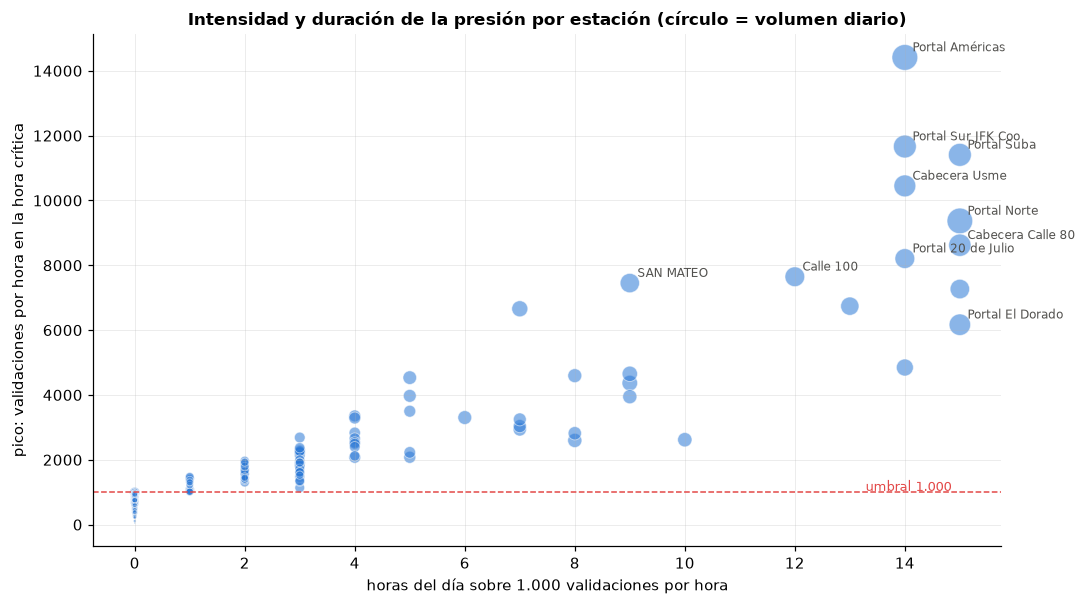

horas sobre el umbral,0,1,2,3,4,5,6,7,8,9,10,12,13,14,15
estaciones,51,14,16,24,9,5,1,4,3,4,1,1,1,5,5


In [7]:
# QUÉ HACE: ubica cada estación según su pico y las horas que pasa sobre el umbral (el tamaño del círculo es el volumen diario) y muestra los dos tipos de presión.
# CÓMO: eje horizontal = horas del día sobre 1.000 validaciones por hora; eje vertical = pico; las estaciones con más carga sobre el umbral se rotulan.
# QUÉ MIRAR: estaciones de pico alto y pocas horas (la presión es corta e intensa) frente a estaciones de pico moderado y muchas horas (presión sostenida); el volumen diario no distingue entre las dos.
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.scatter(m['horas sobre el umbral'], m['pico'], s=m['volumen diario'] / 250, color=COL['hábil'], alpha=0.55, edgecolors='white', linewidths=0.6)
ax.axhline(UMBRAL, color='#e34948', lw=1, ls='--'); ax.text(m['horas sobre el umbral'].max() * 0.99, UMBRAL * 1.04, 'umbral 1.000', fontsize=8.5, color='#e34948', ha='right')
for c, r in m.nlargest(10, 'carga sobre el umbral').iterrows():
    ax.annotate(nombre[c][:18], (r['horas sobre el umbral'], r['pico']), xytext=(5, 4), textcoords='offset points', fontsize=7.8, color='#52514e')
ax.set_xlabel('horas del día sobre 1.000 validaciones por hora'); ax.set_ylabel('pico: validaciones por hora en la hora crítica')
ax.set_title('Intensidad y duración de la presión por estación (círculo = volumen diario)')
plt.tight_layout(); plt.savefig(FIGS / '04_intensidad_duracion.png', bbox_inches='tight'); plt.show()
m['horas sobre el umbral'].value_counts().sort_index().rename('estaciones').to_frame().T

#### ¿Por qué 1.000 y por qué 50 %?

Ninguno de los dos números sale de los datos: son **supuestos de trabajo** que hay que validar con la operación. Para qué sirve cada uno:

- **El umbral de 1.000 validaciones por hora** es la "raya" que separa una hora normal de una hora de presión. Sirve para (1) calcular la carga sobre el umbral que ordena el ranking y (2) marcar las horas de alta presión que el modelo debe anticipar. Su origen es una regla provisional del análisis previo del proyecto (considerar que una estación requiere gestión cuando pasa de 1.000 validaciones por hora); no está calibrado con la capacidad real de los torniquetes ni con la dotación actual.
- **El 50 % del pico** sirve para ubicar la **ventana de refuerzo** alrededor del pico de cada estación. Se necesita porque las estaciones grandes superan 1.000 durante casi todo el día y ese umbral solo no dice *cuándo*. La regla de "la mitad del pico" es una convención habitual para medir el ancho de un pico (su ancho a media altura); se podría usar 40 % o 60 %.

Las dos tablas siguientes muestran **qué cambia si se mueven**: cuántas estaciones y horas quedan marcadas con cada umbral, y cuánto dura la ventana con cada porcentaje.

In [8]:
# QUÉ HACE: muestra el efecto de cambiar el umbral (cuántas celdas estación-hora y cuántas estaciones quedan en alta presión) y el porcentaje del pico (cuánto dura la ventana de refuerzo de algunas estaciones).
# CÓMO: primera tabla: para cada umbral, % de las celdas estación-hora (144 estaciones x 20 horas) que lo superan, estaciones que lo superan alguna hora y % de las validaciones que quedan dentro de esas celdas; segunda tabla: ventana de refuerzo (horas con al menos ese porcentaje del pico y 1.000 o más) para cinco estaciones y cinco porcentajes.
# QUÉ MIRAR: con 1.000 queda en alta presión alrededor del 15 % de las celdas; con valores mayores quedan muy pocas (solo los portales de la mañana); la ventana se hace más corta al subir el porcentaje, pero el momento central (la hora pico) no cambia.
filas = []
for u in [500, 1000, 1500, 2000, 3000, 4000]:
    mk = f >= u
    filas.append({'umbral (validaciones por hora)': u, '% de las celdas en alta presión': mk.values.mean() * 100, 'estaciones que lo superan alguna hora': int(mk.any(axis=1).sum()),
                  '% de las validaciones dentro de esas celdas': f.where(mk).sum().sum() / f.values.sum() * 100})
print('Efecto del umbral:')
display(pd.DataFrame(filas).set_index('umbral (validaciones por hora)').round(1))

def ventana_txt(serie, pct, umbral=UMBRAL):
    lim = max(umbral, pct * serie.max()); horas = [h for h, v in serie.items() if v >= lim]
    if not horas: return '-'
    grupos, ini, prev = [], horas[0], horas[0]
    for h in horas[1:]:
        if h != prev + 1: grupos.append((ini, prev)); ini = h
        prev = h
    grupos.append((ini, prev))
    return f"{len(horas)} h: " + '; '.join(f"{a}-{b + 1}" for a, b in grupos)
casos = {'San Mateo': '07503', 'Portal Américas': '05000', 'Cabecera Calle 80': '04000', 'Portal Norte': '02000', 'Calle 100': '02300'}
print('Efecto del porcentaje del pico en la ventana de refuerzo (horas de la ventana y su ubicación):')
pd.DataFrame({nom_: {f"{int(p * 100)} % del pico": ventana_txt(f.loc[c], p) for p in [0.3, 0.4, 0.5, 0.6, 0.7]} for nom_, c in casos.items()})

Efecto del umbral:


,% de las celdas en alta presión,estaciones que lo superan alguna hora,% de las validaciones dentro de esas celdas
umbral (validaciones por hora),,,
500,32.6,127,79.8
1000,15.7,93,60.7
1500,9.8,68,49.1
2000,6.3,47,39.3
3000,3.2,26,27.6
4000,1.9,18,20.4


Efecto del porcentaje del pico en la ventana de refuerzo (horas de la ventana y su ubicación):


,San Mateo,Portal Américas,Cabecera Calle 80,Portal Norte,Calle 100
30 % del pico,6 h: 4-10,5 h: 4-9,7 h: 5-11; 17-18,13 h: 5-14; 15-19,6 h: 14-20
40 % del pico,5 h: 4-9,5 h: 4-9,5 h: 5-10,7 h: 5-10; 16-18,4 h: 15-19
50 % del pico,4 h: 4-8,3 h: 5-8,3 h: 6-9,5 h: 6-9; 16-18,3 h: 16-19
60 % del pico,3 h: 5-8,3 h: 5-8,3 h: 6-9,3 h: 6-9,3 h: 16-19
70 % del pico,2 h: 5-7,2 h: 5-7,2 h: 6-8,2 h: 6-8,2 h: 16-18


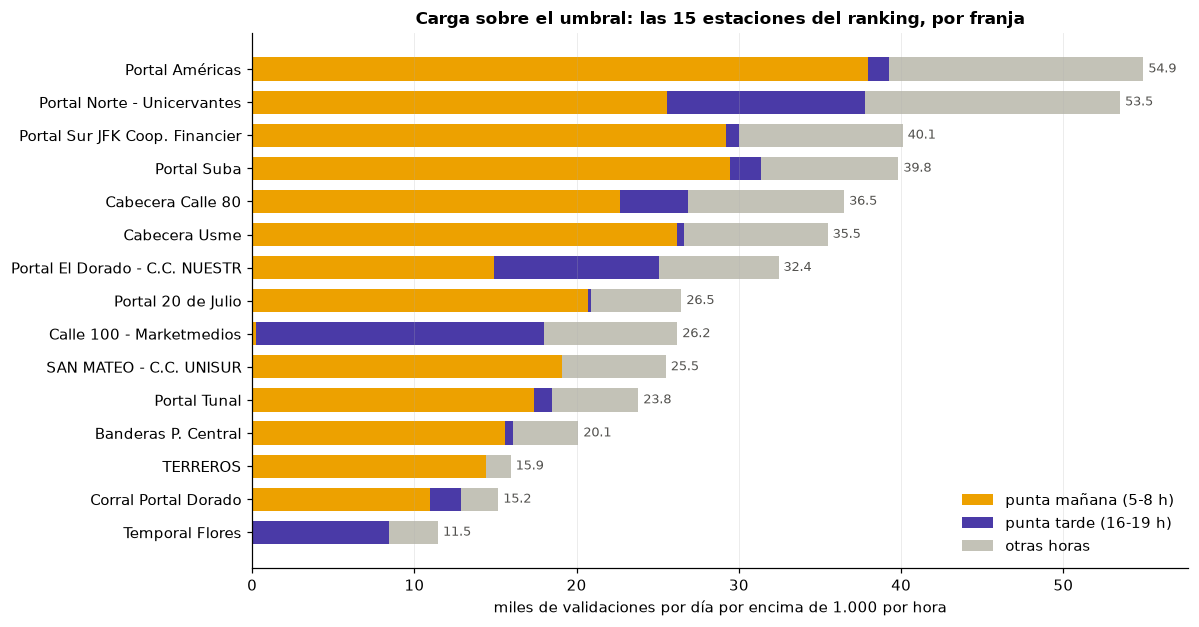

,estación,carga (miles/día),horas sobre el umbral,ventana crítica (>= 50 % del pico),pico (por hora),hora del pico,% carga mañana,% carga tarde
1,Portal Américas,54.9,14,5:00-8:00,14411.6,6,69.1,2.3
2,Portal Norte - Unicervantes,53.5,15,6:00-9:00; 16:00-18:00,9369.2,7,47.7,22.8
3,Portal Sur JFK Coop. Financier,40.1,14,5:00-8:00,11663.7,6,72.8,1.9
4,Portal Suba,39.8,15,5:00-8:00,11407.1,6,73.9,4.8
5,Cabecera Calle 80,36.5,15,6:00-9:00,8619.9,7,62.1,11.5
6,Cabecera Usme,35.5,14,5:00-8:00,10449.1,6,73.7,1.4
7,Portal El Dorado - C.C. NUESTR,32.4,15,6:00-9:00; 16:00-18:00,6167.1,7,45.9,31.4
8,Portal 20 de Julio,26.5,14,5:00-8:00,8207.3,6,78.2,0.7
9,Calle 100 - Marketmedios,26.2,12,16:00-19:00,7646.9,17,0.8,67.8
10,SAN MATEO - C.C. UNISUR,25.5,9,4:00-8:00,7451.5,6,74.9,0.0


In [9]:
# QUÉ HACE: arma el ranking final por carga sobre el umbral y muestra de dónde viene la carga de cada estación (punta de la mañana, punta de la tarde u otras horas) y cuál es su ventana crítica de refuerzo.
# CÓMO: las 15 primeras estaciones por carga sobre el umbral de 1.000 validaciones por hora; las barras separan la carga que cae entre 5 y 8 h, entre 16 y 19 h y en el resto de horas; la ventana crítica son las horas seguidas en que la estación llega al menos al 50 % de su propio pico (con el umbral de 1.000 como mínimo); las estaciones grandes superan 1.000 durante casi todo el día, por eso la ventana se mide contra el pico.
# QUÉ MIRAR: estaciones cuya carga viene casi toda de la mañana (portales), estaciones de la tarde (Calle 100) y estaciones con carga en las dos puntas (Portal Norte); cuántas horas seguidas dura el refuerzo.
def ventanas(serie, umbral=UMBRAL):
    umbral = max(umbral, 0.5 * serie.max())                                     # ventana crítica: horas con al menos 50 % del pico de la propia estación (y no menos de 1.000)
    horas = [h for h, v in serie.items() if v >= umbral]
    if not horas: return '-'
    grupos, ini, prev = [], horas[0], horas[0]
    for h in horas[1:]:
        if h != prev + 1: grupos.append((ini, prev)); ini = h
        prev = h
    grupos.append((ini, prev))
    return '; '.join(f"{a}:00-{b + 1}:00" for a, b in grupos)
exceso = (f - UMBRAL).clip(lower=0)
top15 = m.nlargest(15, 'carga sobre el umbral').index
car = pd.DataFrame({'punta mañana (5-8 h)': exceso.loc[top15, 5:8].sum(axis=1), 'punta tarde (16-19 h)': exceso.loc[top15, 16:19].sum(axis=1)})
car['otras horas'] = exceso.loc[top15].sum(axis=1) - car.sum(axis=1)
fig, ax = plt.subplots(figsize=(11, 5.8))
y = np.arange(len(top15))[::-1]; izq = np.zeros(len(top15))
for col, color in [('punta mañana (5-8 h)', FR['mañana']), ('punta tarde (16-19 h)', FR['tarde']), ('otras horas', '#c3c2b7')]:
    ax.barh(y, car[col] / 1e3, left=izq / 1e3, color=color, height=0.7, label=col); izq += car[col].values
for yi, tot in zip(y, car.sum(axis=1)): ax.text(tot / 1e3 + 0.3, yi, f"{tot / 1e3:.1f}", va='center', fontsize=8.5, color='#52514e')
ax.set_yticks(y); ax.set_yticklabels([est.loc[c, 'nombre'][:30] for c in top15]); ax.grid(axis='y', visible=False)
ax.set_xlabel('miles de validaciones por día por encima de 1.000 por hora'); ax.set_title('Carga sobre el umbral: las 15 estaciones del ranking, por franja'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIGS / '04_ranking_carga_por_franja.png', bbox_inches='tight'); plt.show()
tabla_top = pd.DataFrame({'estación': [est.loc[c, 'nombre'][:30] for c in top15], 'carga (miles/día)': car.sum(axis=1).values / 1e3,
                          'horas sobre el umbral': m.loc[top15, 'horas sobre el umbral'].values, 'ventana crítica (>= 50 % del pico)': [ventanas(f.loc[c]) for c in top15],
                          'pico (por hora)': m.loc[top15, 'pico'].values, 'hora del pico': [int(f.loc[c].idxmax()) for c in top15],
                          '% carga mañana': (car['punta mañana (5-8 h)'] / car.sum(axis=1) * 100).values, '% carga tarde': (car['punta tarde (16-19 h)'] / car.sum(axis=1) * 100).values}, index=range(1, 16))
tabla_top.round(1)

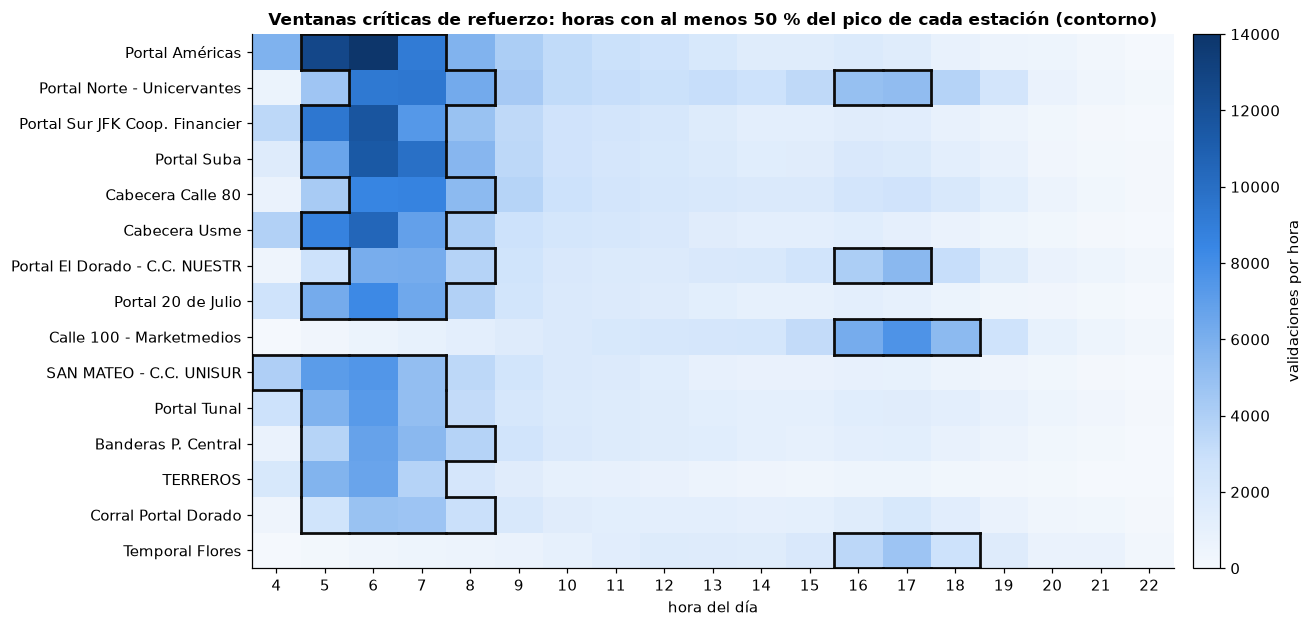

In [10]:
# QUÉ HACE: muestra, para las 15 estaciones del ranking, la demanda hora a hora en un día hábil típico y marca con un contorno su ventana crítica: las horas en que llega al menos al 50 % de su propio pico.
# CÓMO: cada fila es una estación y cada columna una hora de 4 a 22 h; el color es la demanda (validaciones por hora) y el contorno negro encierra las celdas con al menos la mitad del pico de esa estación (y 1.000 o más).
# QUÉ MIRAR: los portales tienen un bloque corto y muy oscuro en la mañana; Calle 100 y las estaciones del centro, un bloque en la tarde; Portal Norte y Calle 80 tienen dos bloques.
from matplotlib.colors import LinearSegmentedColormap
SEC = LinearSegmentedColormap.from_list('sec', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
H = f.loc[top15, 4:22]
fig, ax = plt.subplots(figsize=(12, 5.8))
im = ax.imshow(H.values, aspect='auto', cmap=SEC, vmin=0, vmax=14000, extent=[3.5, 22.5, len(H) - 0.5, -0.5])
umbral_fila = np.maximum(UMBRAL, 0.5 * H.max(axis=1).values)[:, None]
M = H.values >= umbral_fila
for i_ in range(M.shape[0]):
    for j_ in range(M.shape[1]):
        if not M[i_, j_]: continue
        x0, x1, y0, y1 = 3.5 + j_, 4.5 + j_, i_ - 0.5, i_ + 0.5
        if i_ == 0 or not M[i_ - 1, j_]: ax.plot([x0, x1], [y0, y0], color='#0b0b0b', lw=1.8)
        if i_ == M.shape[0] - 1 or not M[i_ + 1, j_]: ax.plot([x0, x1], [y1, y1], color='#0b0b0b', lw=1.8)
        if j_ == 0 or not M[i_, j_ - 1]: ax.plot([x0, x0], [y0, y1], color='#0b0b0b', lw=1.8)
        if j_ == M.shape[1] - 1 or not M[i_, j_ + 1]: ax.plot([x1, x1], [y0, y1], color='#0b0b0b', lw=1.8)
ax.set_yticks(range(len(H))); ax.set_yticklabels([est.loc[c, 'nombre'][:30] for c in H.index]); ax.set_xticks(range(4, 23)); ax.grid(False)
ax.set_xlabel('hora del día'); ax.set_title('Ventanas críticas de refuerzo: horas con al menos 50 % del pico de cada estación (contorno)')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label('validaciones por hora')
plt.tight_layout(); plt.savefig(FIGS / '04_ventanas_de_refuerzo.png', bbox_inches='tight'); plt.show()

### 2.2 Ya con el ranking: ¿por dónde entra la gente en esas estaciones?

El ranking dice **qué estaciones** y **a qué horas**. Falta saber **dónde ubicar al personal dentro de cada estación**. Cada validación indica el **acceso** por el que entró la persona: algunos son plataformas de alimentación (donde llegan los buses zonales y descargan pasajeros de golpe) y otros son accesos peatonales. Se estudian los accesos de las estaciones del ranking.

In [11]:
# QUÉ HACE: cuenta las validaciones de los días hábiles por estación, acceso y hora, y clasifica cada acceso en "alimentación" (plataforma de buses zonales) o "peatonal / otro".
# CÓMO: Dask agrupa por (estación, acceso, hora); un acceso es de alimentación si su nombre contiene ALIM, PLAT o DESAL (hay ~430 nombres distintos escritos de muchas formas); los valores son promedios de un día hábil.
# QUÉ MIRAR: ~21 % de las validaciones entra por alimentación, pero concentrado en pocas estaciones (los portales).
# (Este conteo se usa en el resto de la sección para las estaciones del ranking.)
t0 = time.perf_counter()
vb = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada', 'Acceso_Estacion'])
vb = vb[vb['Fecha_Transaccion'].str[:10].isin(habiles)]
acc = (vb.assign(cod_estacion=vb['Estacion_Parada'].str[1:6], hora=vb['Fecha_Transaccion'].str[11:13].astype('int64'))
         .groupby(['cod_estacion', 'Acceso_Estacion', 'hora']).size().compute().rename('validaciones').reset_index())
acc['validaciones'] = acc['validaciones'] / len(habiles)
acc['clase'] = np.where(acc['Acceso_Estacion'].str.upper().str.contains('ALIM|PLAT|DESAL'), 'alimentación', 'peatonal / otro')
print(f"Conteo por acceso en {time.perf_counter() - t0:.0f} s | {acc['Acceso_Estacion'].nunique()} nombres de acceso distintos")
ra = acc.groupby('clase').agg(nombres=('Acceso_Estacion', 'nunique'), val_por_dia=('validaciones', 'sum'))
ra['% de las validaciones'] = ra['val_por_dia'] / ra['val_por_dia'].sum() * 100
alim = acc[acc['clase'] == 'alimentación'].groupby('cod_estacion')['validaciones'].sum()
est['pct_alimentacion'] = alim.reindex(est.index).fillna(0) / est['val_dia'] * 100
print(f"Estaciones con más de 60 % de la demanda por alimentación: {int((est.loc[act, 'pct_alimentacion'] > 60).sum())} | con menos de 5 %: {int((est.loc[act, 'pct_alimentacion'] < 5).sum())}")
ra.round(1)

Conteo por acceso en 18 s | 432 nombres de acceso distintos
Estaciones con más de 60 % de la demanda por alimentación: 10 | con menos de 5 %: 130


,nombres,val_por_dia,% de las validaciones
clase,,,
alimentación,115,397107.2,21.4
peatonal / otro,317,1455148.1,78.6


In [12]:
# QUÉ HACE: mide cómo llega la gente dentro de la hora crítica de cada estación del ranking: qué parte entra en los primeros 20, los 20 del medio y los últimos 20 minutos, y cuánto sube la demanda en el cuarto de hora más cargado.
# CÓMO: Dask cuenta las validaciones por minuto de las 15 estaciones en los 14 días hábiles; el "cuarto de hora más cargado" es la ventana de 15 minutos con más validaciones y se expresa como validaciones por hora (x 4) para comparar con el promedio de la hora.
# QUÉ MIRAR: si el pico dentro de la hora es bastante mayor que el promedio horario (en ese caso el conteo por hora subestima la presión) y en qué parte de la hora cae.
t0 = time.perf_counter()
t15 = list(top15)
vm = dd.read_parquet(str(VALIDACIONES), columns=['Fecha_Transaccion', 'Estacion_Parada'])
vm = vm[vm['Fecha_Transaccion'].str[:10].isin(habiles)]
vm = vm.assign(cod=vm['Estacion_Parada'].str[1:6]); vm = vm[vm['cod'].isin(t15)]
vm = vm.assign(minuto=vm['Fecha_Transaccion'].str[11:13].astype('int64') * 60 + vm['Fecha_Transaccion'].str[14:16].astype('int64'))
mc = vm.groupby(['cod', 'minuto']).size().compute().rename('n').reset_index()
print(f"Conteo por minuto de las 15 estaciones en {time.perf_counter() - t0:.0f} s")
filas = []
for c in t15:
    s_ = mc[mc['cod'] == c].set_index('minuto')['n'].reindex(range(1440), fill_value=0) / len(habiles)
    h = int(est.loc[c, 'hora_pico']); bloque = s_.iloc[h * 60:(h + 1) * 60].values
    r15 = s_.rolling(15).sum(); fin15 = int(r15.idxmax()); pico15 = r15.max() * 4
    filas.append({'estación': est.loc[c, 'nombre'][:26], 'hora del pico': h, 'promedio de la hora': bloque.sum(), '% en minutos 0-19': bloque[:20].sum() / bloque.sum() * 100,
                  '% en minutos 20-39': bloque[20:40].sum() / bloque.sum() * 100, '% en minutos 40-59': bloque[40:].sum() / bloque.sum() * 100,
                  'cuarto de hora más cargado': f"{(fin15 - 14) // 60}:{(fin15 - 14) % 60:02d}", 'ritmo en ese cuarto de hora (por hora)': pico15, 'aumento frente a la hora (%)': (pico15 / s_.iloc[(fin15 - 14) // 60 * 60:((fin15 - 14) // 60 + 1) * 60].sum() - 1) * 100})
dentro_hora = pd.DataFrame(filas, index=range(1, 16))
dentro_hora.round(1)

Conteo por minuto de las 15 estaciones en 12 s


,estación,hora del pico,promedio de la hora,% en minutos 0-19,% en minutos 20-39,% en minutos 40-59,cuarto de hora más cargado,ritmo en ese cuarto de hora (por hora),aumento frente a la hora (%)
1,Portal Américas,6,14411.6,32.7,34.9,32.4,6:19,15269.7,6.0
2,Portal Norte - Unicervante,7,9369.2,36.9,35.7,27.4,7:16,10860.9,15.9
3,Portal Sur JFK Coop. Finan,6,11663.7,32.9,35.1,32.0,6:22,12865.1,10.3
4,Portal Suba,6,11407.1,31.6,33.4,35.1,6:56,12658.6,11.0
5,Cabecera Calle 80,7,8619.9,38.7,34.0,27.3,7:07,10257.1,19.0
6,Cabecera Usme,6,10449.1,32.9,34.2,32.9,6:35,11003.7,5.3
7,Portal El Dorado - C.C. NU,7,6167.1,38.6,33.8,27.6,7:02,7211.1,16.9
8,Portal 20 de Julio,6,8207.3,32.1,34.0,33.8,6:51,8537.7,4.0
9,Calle 100 - Marketmedios,17,7646.9,33.4,36.1,30.5,17:17,8443.4,10.4
10,SAN MATEO - C.C. UNISUR,6,7451.5,35.0,34.3,30.7,6:08,7933.1,6.5


### 2.3 Un ranking por franja y la presión respecto al espacio

El ranking general está dominado por los portales de la mañana, que son estaciones grandes (varias plataformas y muchos accesos). Dos ajustes:

1. **Un ranking por franja**, para que la punta de la tarde tenga el suyo y no quede tapada por la mañana.
2. **La presión respecto al espacio**: una estación pequeña con mucho flujo puede ser más difícil de ordenar que un portal con más demanda. El archivo oficial trae el **área (m²)** de 117 de las 144 estaciones, pero de **ningún portal ni cabecera**; para esas estaciones se usan los **accesos activos** (los que aportan 10 % o más de la hora crítica) como medida de espacio. El m² es el área de la estación, no el área disponible para la fila: es una medida aproximada.

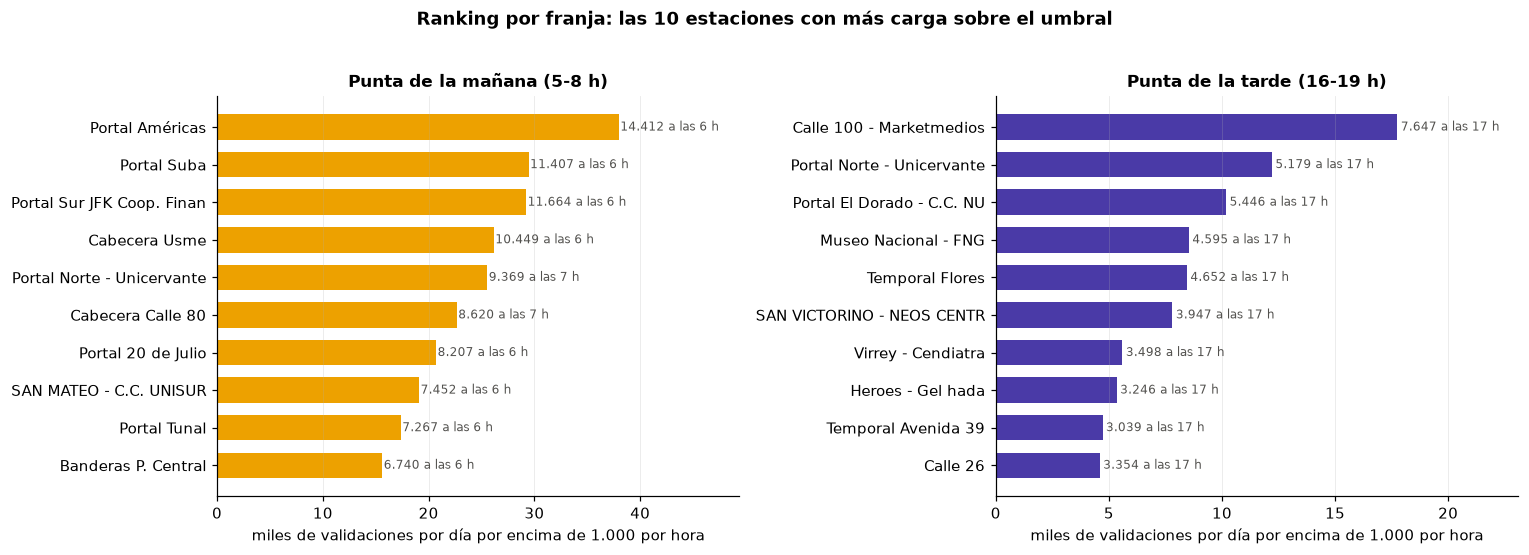

Top 10 de la punta de la mañana:


,estación,hora crítica,pico,carga sobre el umbral,accesos activos,% acceso principal,m²,pico por m²,pico por acceso activo,puesto por m²,puesto por acceso
cod_estacion,,,,,,,,,,,
05000,Portal Américas,6,14411.6,37976.3,3,41.2,NaN,NaN,4803.9,NaN,1
03000,Portal Suba,6,11407.1,29450.7,3,35.3,NaN,NaN,3802.4,NaN,2
07000,Portal Sur JFK Coop. Financi,6,11663.7,29215.1,4,25.6,NaN,NaN,2915.9,NaN,6
09000,Cabecera Usme,6,10449.1,26157.1,3,32.8,NaN,NaN,3483.0,NaN,4
02000,Portal Norte - Unicervantes,7,9369.2,25544.4,4,31.5,NaN,NaN,2342.3,NaN,11
04000,Cabecera Calle 80,7,8619.9,22658.0,4,32.1,NaN,NaN,2155.0,NaN,14
10000,Portal 20 de Julio,6,8207.3,20705.9,3,54.8,NaN,NaN,2735.8,NaN,7
07503,SAN MATEO - C.C. UNISUR,6,7451.5,19100.7,2,66.7,492.8,15.1,3725.8,3.0,3
08000,Portal Tunal,6,7267.4,17367.0,3,33.2,NaN,NaN,2422.5,NaN,10


Top 10 de la punta de la tarde:


,estación,hora crítica,pico,carga sobre el umbral,accesos activos,% acceso principal,m²,pico por m²,pico por acceso activo,puesto por m²,puesto por acceso
cod_estacion,,,,,,,,,,,
02300,Calle 100 - Marketmedios,17,7646.9,17758.7,2,54.9,814.4,9.4,3823.4,1.0,1
02000,Portal Norte - Unicervantes,17,5179.2,12212.6,4,28.3,NaN,NaN,1294.8,NaN,39
06000,Portal El Dorado - C.C. NUES,17,5445.7,10188.8,4,45.4,NaN,NaN,1361.4,NaN,31
10009,Museo Nacional - FNG,17,4595.4,8542.6,2,60.5,NaN,NaN,2297.7,NaN,8
09127,Temporal Flores,17,4652.1,8455.6,2,61.4,NaN,NaN,2326.0,NaN,7
10006,SAN VICTORINO - NEOS CENTRO,17,3947.1,7812.6,2,49.0,791.2,5.0,1973.6,12.0,14
02302,Virrey - Cendiatra,17,3498.4,5602.6,1,99.9,773.1,4.5,3498.4,17.0,2
02304,Heroes - Gel hada,17,3245.6,5349.1,1,100.0,669.6,4.8,3245.6,15.0,3
09130,Temporal Avenida 39,17,3039.3,4721.5,2,52.1,NaN,NaN,1519.6,NaN,22


In [13]:
# QUÉ HACE: arma, para cada punta (mañana 5-8 h y tarde 16-19 h), la tabla de estaciones con su demanda, su espacio (m² y accesos activos) y los puestos que ocupa por demanda y por presión respecto al espacio; dibuja el top 10 de cada punta.
# CÓMO: demanda = carga sobre 1.000 validaciones por hora dentro de la franja; presión = pico de la franja por m² (si hay área) y por acceso activo; los puestos se calculan entre las estaciones que tienen el dato.
# QUÉ MIRAR: estaciones que suben mucho al medir la presión (pequeñas con mucho flujo) frente a las que dependen del tamaño; que la tarde tiene su propio ranking (Calle 100 primera).
FR_H = {'mañana': (5, 8), 'tarde': (16, 19)}
def info_accesos(c, h):
    a = acc[(acc['cod_estacion'] == c) & (acc['hora'] == h)].sort_values('validaciones', ascending=False); tot = a['validaciones'].sum()
    if tot <= 0: return np.nan, '', np.nan
    return int((a['validaciones'] / tot >= 0.10).sum()), a['Acceso_Estacion'].iloc[0], a['validaciones'].iloc[0] / tot * 100
tablas = {}
for k, (a_, z_) in FR_H.items():
    sub = por_est_hora.loc[act, a_:z_]
    t = pd.DataFrame({'estación': est.loc[act, 'nombre'].str[:28], 'hora crítica': sub.idxmax(axis=1), 'pico': sub.max(axis=1), 'carga sobre el umbral': (sub - UMBRAL).clip(lower=0).sum(axis=1)})
    inf = [info_accesos(c, int(h)) for c, h in t['hora crítica'].items()]
    t['accesos activos'] = [i[0] for i in inf]; t['acceso principal'] = [i[1][:24] for i in inf]; t['% acceso principal'] = [i[2] for i in inf]
    t['m²'] = est.loc[act, 'area_m2']; t['pico por m²'] = t['pico'] / t['m²']; t['pico por acceso activo'] = t['pico'] / t['accesos activos']
    t['puesto por demanda'] = t['carga sobre el umbral'].rank(ascending=False).astype(int)
    t['puesto por m²'] = t['pico por m²'].rank(ascending=False)
    t['puesto por acceso'] = t['pico por acceso activo'].rank(ascending=False).astype(int)
    tablas[k] = t.sort_values('carga sobre el umbral', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
for ax, (k, t), titulo in zip(axes, tablas.items(), ['Punta de la mañana (5-8 h)', 'Punta de la tarde (16-19 h)']):
    d_ = t.head(10).iloc[::-1]
    ax.barh(d_['estación'].str[:26], d_['carga sobre el umbral'] / 1e3, color=FR[k], height=0.68)
    for p, (_, r) in zip(ax.patches, d_.iterrows()): ax.text(p.get_width() + 0.15, p.get_y() + p.get_height() / 2, f"{r['pico']:,.0f} a las {int(r['hora crítica'])} h".replace(',', '.'), va='center', fontsize=8, color='#52514e')
    ax.set_title(titulo); ax.set_xlabel('miles de validaciones por día por encima de 1.000 por hora'); ax.grid(axis='y', visible=False); ax.set_xlim(0, d_['carga sobre el umbral'].max() / 1e3 * 1.3)
fig.suptitle('Ranking por franja: las 10 estaciones con más carga sobre el umbral', fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(FIGS / '04_ranking_por_franja.png', bbox_inches='tight'); plt.show()
for k in tablas:
    print(f"Top 10 de la punta de la {k}:")
    display(tablas[k].head(10)[['estación', 'hora crítica', 'pico', 'carga sobre el umbral', 'accesos activos', '% acceso principal', 'm²', 'pico por m²', 'pico por acceso activo', 'puesto por m²', 'puesto por acceso']].round(1))

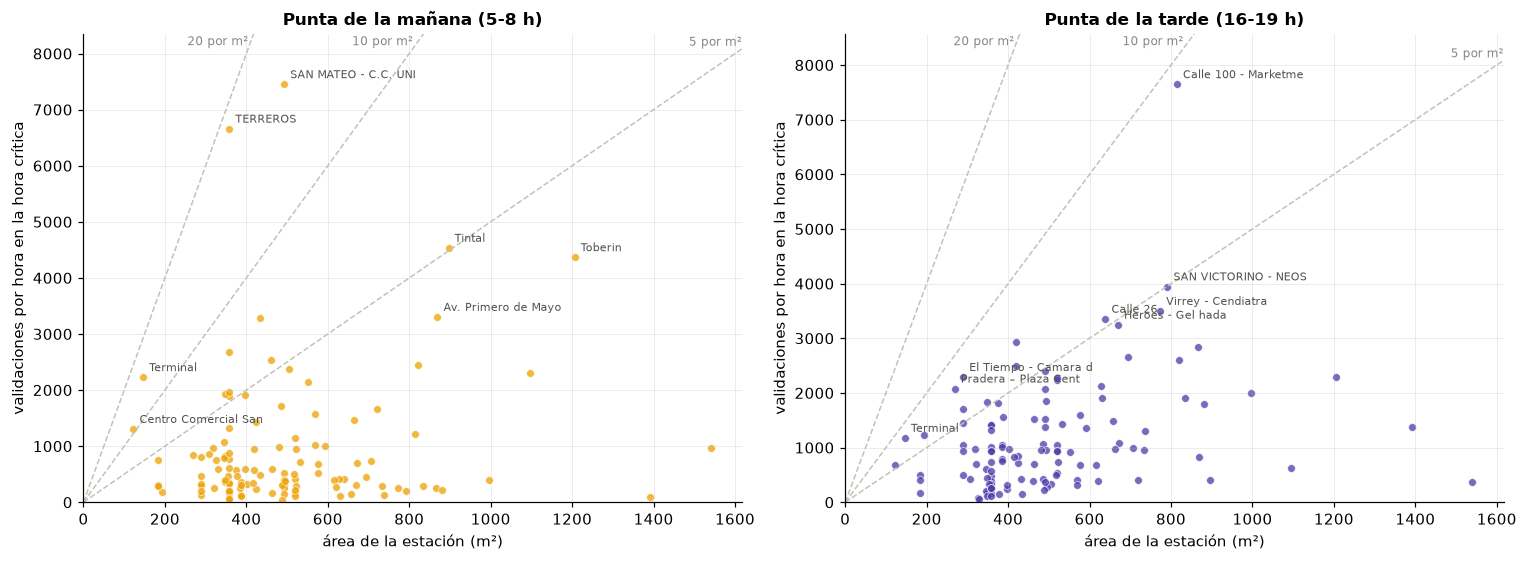

Estaciones del top 10 de cada punta que también están entre las 10 de mayor presión (por m² o por acceso activo):


,franja,estación,puesto por demanda,pico,m²,puesto por m²,puesto por acceso,crítica en ambos criterios
0,mañana,Portal Américas,1,14411.6,NaN,NaN,1,True
1,mañana,Portal Suba,2,11407.1,NaN,NaN,2,True
2,mañana,Portal Sur JFK Coop. Financi,3,11663.7,NaN,NaN,6,True
3,mañana,Cabecera Usme,4,10449.1,NaN,NaN,4,True
4,mañana,Portal 20 de Julio,7,8207.3,NaN,NaN,7,True
5,mañana,SAN MATEO - C.C. UNISUR,8,7451.5,492.8,3.0,3,True
6,mañana,Portal Tunal,9,7267.4,NaN,NaN,10,True
7,tarde,Calle 100 - Marketmedios,1,7646.9,814.4,1.0,1,True
8,tarde,Museo Nacional - FNG,4,4595.4,NaN,NaN,8,True
9,tarde,Temporal Flores,5,4652.1,NaN,NaN,7,True


In [14]:
# QUÉ HACE: dibuja, para cada punta, el pico de cada estación frente a su área (m²), con rectas de presión constante (validaciones por hora por m²), y cuenta las estaciones que son críticas por demanda y también por presión.
# CÓMO: solo estaciones con área en el archivo oficial (ningún portal); las rectas punteadas son 5, 10 y 20 validaciones por hora por m²; una estación es crítica en ambos criterios si está en el top 10 por carga y entre las 10 de mayor presión por m² o por acceso activo.
# QUÉ MIRAR: estaciones por encima de las rectas (poco espacio y mucho flujo): San Mateo y Terreros en la mañana, Calle 100 en la tarde; cuáles quedan críticas por los dos criterios.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, (k, t), titulo in zip(axes, tablas.items(), ['Punta de la mañana (5-8 h)', 'Punta de la tarde (16-19 h)']):
    d_ = t.dropna(subset=['m²'])
    ax.scatter(d_['m²'], d_['pico'], s=26, color=FR[k], alpha=0.75, edgecolors='white', linewidths=0.5)
    ymax = d_['pico'].max() * 1.12; xs = np.linspace(0, d_['m²'].max() * 1.05, 50)
    for kk in [5, 10, 20]:
        xe = min(xs[-1], ymax / kk * 0.97); ax.plot(xs, kk * xs, color='#c3c2b7', lw=1, ls='--'); ax.text(xe, kk * xe, f"{kk} por m²", fontsize=8, color='#898781', ha='right', va='bottom')
    for c, r in pd.concat([d_.nlargest(5, 'pico'), d_.nlargest(4, 'pico por m²')]).drop_duplicates().iterrows(): ax.annotate(r['estación'][:20], (r['m²'], r['pico']), xytext=(4, 4), textcoords='offset points', fontsize=7.5, color='#52514e')
    ax.set_xlim(0, d_['m²'].max() * 1.05); ax.set_ylim(0, ymax); ax.set_xlabel('área de la estación (m²)'); ax.set_ylabel('validaciones por hora en la hora crítica'); ax.set_title(titulo)
plt.tight_layout(); plt.savefig(FIGS / '04_presion_vs_m2.png', bbox_inches='tight'); plt.show()
filas = []
for k, t in tablas.items():
    for c, r in t.head(10).iterrows():
        filas.append({'franja': k, 'estación': r['estación'], 'puesto por demanda': r['puesto por demanda'], 'pico': r['pico'], 'm²': r['m²'], 'puesto por m²': r['puesto por m²'], 'puesto por acceso': r['puesto por acceso'],
                      'crítica en ambos criterios': bool((pd.notna(r['puesto por m²']) and r['puesto por m²'] <= 10) or r['puesto por acceso'] <= 10)})
cr = pd.DataFrame(filas)
print('Estaciones del top 10 de cada punta que también están entre las 10 de mayor presión (por m² o por acceso activo):')
cr[cr['crítica en ambos criterios']].round(1).reset_index(drop=True)

In [15]:
# QUÉ HACE: mide qué tan estable es el pico de cada estación del ranking de un día hábil a otro, con su margen de error (intervalo del 95 % del promedio de 14 días).
# CÓMO: para cada estación se toman las validaciones de su hora del pico en cada uno de los 14 días hábiles; coeficiente de variación = desviación / promedio; semiancho del intervalo = t(0,975; 13) · s / √14.
# QUÉ MIRAR: coeficientes de variación pequeños (el pico se repite casi igual todos los días) y márgenes de error de pocos puntos porcentuales: el ranking es confiable.
from scipy import stats
filas = []
for c in top15:
    h = int(est.loc[c, 'hora_pico']); v = cubo.loc[c].xs(h, level='hora').values.astype(float)
    filas.append({'estación': est.loc[c, 'nombre'][:28], 'hora del pico': h, 'promedio': v.mean(), 'mínimo': v.min(), 'máximo': v.max(), 'coef. de variación (%)': v.std(ddof=1) / v.mean() * 100,
                  'margen IC 95 % (%)': stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)) / v.mean() * 100})
estab = pd.DataFrame(filas, index=range(1, 16))
print(f"Coeficiente de variación mediano del pico: {estab['coef. de variación (%)'].median():.1f} % | margen mediano del intervalo: ± {estab['margen IC 95 % (%)'].median():.1f} %")
estab.round(1)

Coeficiente de variación mediano del pico: 4.6 % | margen mediano del intervalo: ± 2.6 %


,estación,hora del pico,promedio,mínimo,máximo,coef. de variación (%),margen IC 95 % (%)
1,Portal Américas,6,14411.6,13383.0,15308.0,4.6,2.6
2,Portal Norte - Unicervantes,7,9369.2,8514.0,10085.0,5.4,3.1
3,Portal Sur JFK Coop. Financi,6,11663.7,9516.0,12555.0,6.7,3.9
4,Portal Suba,6,11407.1,10819.0,11947.0,2.9,1.7
5,Cabecera Calle 80,7,8619.9,8089.0,9280.0,3.7,2.1
6,Cabecera Usme,6,10449.1,9854.0,11622.0,4.2,2.4
7,Portal El Dorado - C.C. NUES,7,6167.1,5536.0,6759.0,5.4,3.1
8,Portal 20 de Julio,6,8207.3,7461.0,8822.0,3.9,2.3
9,Calle 100 - Marketmedios,17,7646.9,6143.0,8319.0,9.2,5.3
10,SAN MATEO - C.C. UNISUR,6,7451.5,7229.0,7860.0,2.3,1.3


In [16]:
# QUÉ HACE: reúne en una sola tabla el ranking final con todo lo que se sabe de cada estación: cuándo, cuánto, por dónde, qué tan estable y con qué densidad.
# CÓMO: une las tablas anteriores; la densidad por m² solo existe para las estaciones con área en el archivo oficial.
# QUÉ MIRAR: esta tabla es la respuesta descriptiva a la pregunta: qué estaciones, en qué ventanas, por qué acceso y con qué margen.
prio = tabla_top[['estación', 'carga (miles/día)', 'ventana crítica (>= 50 % del pico)', 'pico (por hora)']].copy()
prio['acceso principal'] = [acc[(acc['cod_estacion'] == c) & (acc['hora'] == int(est.loc[c, 'hora_pico']))].sort_values('validaciones', ascending=False)['Acceso_Estacion'].iloc[0][:26] for c in top15]
prio['ritmo en el cuarto de hora más cargado'] = dentro_hora['ritmo en ese cuarto de hora (por hora)'].values
prio['coef. de variación (%)'] = estab['coef. de variación (%)'].values
prio['validaciones por hora por m²'] = [est.loc[c, 'val_hora_pico'] / est.loc[c, 'area_m2'] if pd.notna(est.loc[c, 'area_m2']) else np.nan for c in top15]
prio.round(1)

,estación,carga (miles/día),ventana crítica (>= 50 % del pico),pico (por hora),acceso principal,ritmo en el cuarto de hora más cargado,coef. de variación (%),validaciones por hora por m²
1,Portal Américas,54.9,5:00-8:00,14411.6,(23) Acceso Peatonal,15269.7,4.6,NaN
2,Portal Norte - Unicervantes,53.5,6:00-9:00; 16:00-18:00,9369.2,(02) PLATAFORMA 2 ALIMENTA,10860.9,5.4,NaN
3,Portal Sur JFK Coop. Financier,40.1,5:00-8:00,11663.7,(KB) PLATAFORMA 1 ALIMENTA,12865.1,6.7,NaN
4,Portal Suba,39.8,5:00-8:00,11407.1,(07) ALIMENTACIÓN PLATAFOR,12658.6,2.9,NaN
5,Cabecera Calle 80,36.5,6:00-9:00,8619.9,(16) Acceso Peatonal,10257.1,3.7,NaN
6,Cabecera Usme,35.5,5:00-8:00,10449.1,(4A) Peatonal,11003.7,4.2,NaN
7,Portal El Dorado - C.C. NUESTR,32.4,6:00-9:00; 16:00-18:00,6167.1,(23) Acceso Túnel PLAT2 Al,7211.1,5.4,NaN
8,Portal 20 de Julio,26.5,5:00-8:00,8207.3,(01) ALIMENTACIÓN JUAN REY,8537.7,3.9,NaN
9,Calle 100 - Marketmedios,26.2,16:00-19:00,7646.9,(01) Acceso Norte,8443.4,9.2,9.4
10,SAN MATEO - C.C. UNISUR,25.5,4:00-8:00,7451.5,(01) Acceso Peatonal Sur,7933.1,2.3,15.1


### Lectura del paso 2: respuesta descriptiva a la pregunta

**1. Cuándo se concentra la demanda.** Dos puntas: la de la mañana (5 a 8 h) mueve 159 mil validaciones por hora y reúne 34 % del día en 4 horas; la de la tarde (16 a 19 h) mueve 133 mil por hora (29 %). El valle mueve 83 mil por hora y la madrugada y la noche suman 5 %. Pocas estaciones concentran la demanda: 26 de 144 reúnen la mitad de las validaciones.

**2. Cómo se midió la necesidad de refuerzo.** Se compararon cuatro medidas: volumen diario, pico, horas sobre el umbral y carga sobre el umbral (intensidad y duración juntas). Los rankings son muy parecidos (Spearman entre 0,93 y 0,98; entre 8 y 9 de las 10 primeras coinciden) y el ranking por carga casi no cambia al mover el umbral de 1.000 a 500 (Spearman 0,96) o a 2.000 (0,85); las 10 primeras son las mismas. El resultado no depende de una elección arbitraria.

**3. Ranking general (carga sobre 1.000 validaciones por hora).** Portal Américas (54,9 mil validaciones por día por encima del umbral), Portal Norte (53,5), Portal Sur (40,1), Portal Suba (39,8), Cabecera Calle 80 (36,5), Cabecera Usme (35,5), Portal El Dorado (32,4), Portal 20 de Julio (26,5), Calle 100 (26,2) y San Mateo (25,5). Hay 51 estaciones que nunca superan 1.000 por hora.

**4. Tipo de presión y ventana crítica.** Los portales y cabeceras superan 1.000 durante 14 o 15 horas, por lo que el umbral no sirve para decir *cuándo* reforzar; la **ventana crítica** se define como las horas con al menos el 50 % del pico de la propia estación: 5:00-8:00 en Portal Américas, Sur, Suba, Usme, 20 de Julio, Tunal y Terreros; 6:00-9:00 en Portal Norte, Calle 80 y El Dorado (que tienen además una segunda ventana de 16:00 a 18:00); 16:00-19:00 en Calle 100 y Temporal Flores. San Mateo (9 horas sobre el umbral) y Terreros (7) son de presión corta e intensa.

**5. Por dónde entra la gente.** En la hora del pico el acceso principal de las estaciones del ranking concentra entre 26 % y 67 % de la demanda y hay entre 2 y 5 accesos con 10 % o más. En los portales entre 59 % y 84 % de la demanda del día llega por alimentación (oleadas de buses zonales), por lo que el personal debe cubrir las plataformas además del acceso peatonal. Casos con un acceso dominante: San Mateo (peatonal sur, 67 %), Terreros (peatonal norte, 58 %), Calle 100 (norte, 55 %) y Temporal Flores (61 %).

**6. Cómo llega la gente dentro de la hora crítica.** El reparto entre los primeros, los del medio y los últimos 20 minutos es casi parejo (entre 27 % y 39 % en cada tercio). El cuarto de hora más cargado supera el promedio de su hora entre 4 % y 19 % (Cabecera Calle 80 +19 %, El Dorado +17 %, Portal Norte +16 %); en Portal Américas el ritmo llega a 15.270 validaciones por hora entre las 6:19 y las 6:34. El conteo por hora subestima algo la presión.

**7. Un ranking por franja.** El ranking general queda dominado por los portales de la mañana; por eso se calculó uno por punta.
- **Mañana:** Portal Américas (14.412 por hora a las 6 h), Suba, Sur, Cabecera Usme, Portal Norte, Calle 80, 20 de Julio, **San Mateo (7.452)**, Tunal y Banderas.
- **Tarde:** **Calle 100 (7.647 por hora a las 17 h)** va primera con ventaja (carga de 17,8 mil frente a 12,2 mil de la segunda, Portal Norte); siguen Portal Norte (5.179), El Dorado (5.446), Museo Nacional (4.595), Temporal Flores (4.652), San Victorino, Virrey, Héroes, Temporal Avenida 39 y Calle 26. La tarde tiene picos menores (el segundo no pasa de 5,4 mil) y más estaciones céntricas con uno o dos accesos.

**8. Presión respecto al espacio.** El archivo oficial tiene el área (m²) de 117 de las 144 estaciones, pero de ningún portal ni cabecera de los 10 mayores; para esas se usa el número de accesos activos. El m² es el área de la estación, no el de la fila: es una medida aproximada.
- **Mañana, entre las que tienen m²:** Terreros (18,6 validaciones por hora por m²), Terminal (15,2) y **San Mateo (15,1; puesto 3)**; por acceso activo, Portal Américas (4.804 por acceso), Suba (3.802) y San Mateo (3.726) son las tres primeras.
- **Tarde:** **Calle 100 es la primera por m² (9,4) y por acceso activo (3.823)**; Virrey (3.498) y Héroes (3.246) quedan segundas y terceras por acceso, porque toda su demanda de la hora entra por un único acceso, aunque su demanda total es menor.
- **Críticas en ambos criterios** (top 10 por demanda y entre las 10 de mayor presión): en la mañana, Portal Américas, Suba, Sur, Usme, 20 de Julio, San Mateo y Tunal; en la tarde, Calle 100, Museo Nacional, Temporal Flores, Virrey y Héroes.
- El criterio de presión cambia poco el top de la mañana, pero **sube a estaciones pequeñas en la tarde** (Virrey, Héroes) y confirma a San Mateo y a Calle 100.

**9. Confiabilidad.** El pico de las estaciones del ranking se repite casi igual cada día: coeficiente de variación mediano de 4,6 % y margen del intervalo del 95 % de ± 2,6 %. Las más estables son San Mateo y Terreros (2,3 %); las menos, Calle 100 (9,2 %) y Temporal Flores (15,3 %, una estación temporal).

**Respuesta a la pregunta.** Las estaciones que más justifican refuerzo son, en la **punta de la mañana (5:00 a 9:00)**, los portales y cabeceras de la periferia y San Mateo y Terreros (pequeñas y densas), y en la **punta de la tarde (16:00 a 19:00)**, Calle 100, Portal Norte, Portal El Dorado y las estaciones del centro (Museo Nacional, Virrey, Héroes). La tabla final del paso 2 reúne, para cada una del ranking, la ventana, el acceso principal, el ritmo en el cuarto de hora más cargado, su estabilidad y la densidad por m² cuando se conoce.

## 3. Patrones de las estaciones: ¿hay estaciones de mañana y estaciones de tarde?

En una zona residencial la gente entra a la estación **en la mañana** (para ir al trabajo) y casi no entra en la tarde; en una zona de destino ocurre lo contrario. Para verlo se compara la **forma del día** de cada estación (el porcentaje de su demanda diaria que cae en cada hora) y se agrupan las estaciones con formas parecidas con **K-Means** (4 grupos).

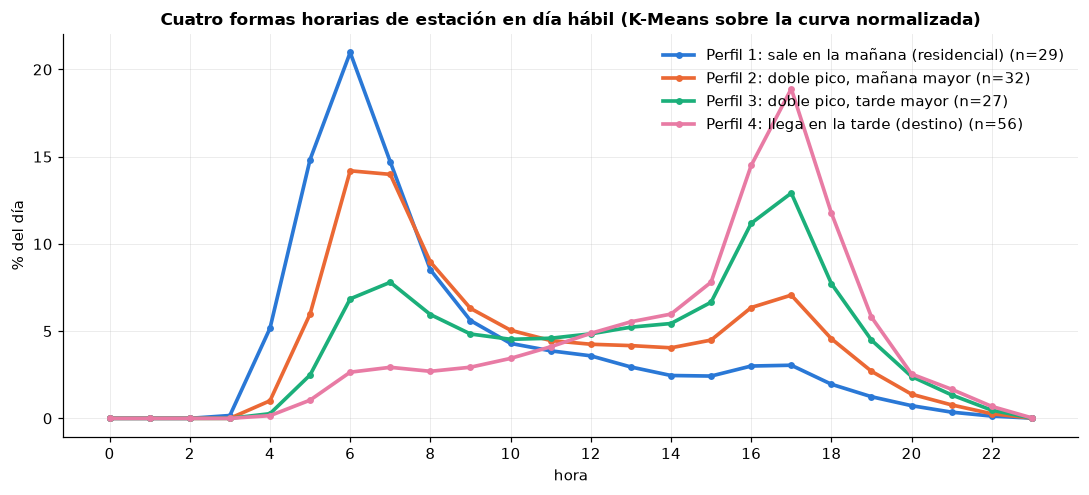

,estaciones,% de las validaciones,% del día en 5-8 h,% del día en 16-19 h,hora crítica típica,km al centro (mediana),% por alimentación,ejemplos (mayor demanda)
Perfil 1: sale en la mañana (residencial),29,32.9,59.0,9.2,6,8.9,18.7,"Portal Américas, Portal Suba, Portal Sur JFK Coo"
"Perfil 2: doble pico, mañana mayor",32,22.3,43.1,20.7,7,9.3,9.0,"Portal Norte, Cabecera Calle 80, Portal El Dorado"
"Perfil 3: doble pico, tarde mayor",27,10.8,23.1,36.3,17,8.4,0.0,"Temporal Marly, Alcalá – Colegio S, Pradera – Plaza Ce"
Perfil 4: llega en la tarde (destino),56,32.1,9.3,51.0,17,5.3,0.6,"Calle 100, Temporal Flores, SAN VICTORINO"


In [17]:
# QUÉ HACE: agrupa las estaciones activas según la forma de su día (porcentaje de la demanda diaria en cada hora) con K-Means y dibuja la curva promedio de cada grupo.
# CÓMO: cada estación se describe con 24 números (% del día por hora); K-Means forma 4 grupos con formas parecidas; los grupos se ordenan por la hora media de entrada (el 1 es el más madrugador).
# QUÉ MIRAR: un grupo con pico fuerte a las 6 h y casi nada en la tarde (residencial); un grupo con pico fuerte a las 17 h (destino); y grupos de doble pico.
X = por_est_hora.loc[act].div(por_est_hora.loc[act].sum(axis=1), axis=0) * 100
km = KMeans(n_clusters=4, random_state=0, n_init=10).fit(X.values)
hora_media_c = pd.Series({k: (km.cluster_centers_[k] * np.arange(24)).sum() / 100 for k in range(4)}).sort_values()
nuevo = {k: i + 1 for i, k in enumerate(hora_media_c.index)}
est['perfil'] = pd.Series(km.labels_, index=X.index).map(nuevo).reindex(est.index)
centros = pd.DataFrame(km.cluster_centers_, columns=range(24)); centros.index = [nuevo[k] for k in centros.index]; centros = centros.sort_index()
CP = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a', 4: '#e87ba4'}
PERFIL = {1: 'sale en la mañana (residencial)', 2: 'doble pico, mañana mayor', 3: 'doble pico, tarde mayor', 4: 'llega en la tarde (destino)'}   # nombres según las curvas de abajo
fig, ax = plt.subplots(figsize=(10, 4.6))
for k, c in CP.items():
    ax.plot(range(24), centros.loc[k], color=c, lw=2.4, marker='o', ms=3.5, label=f"Perfil {k}: {PERFIL[k]} (n={int((est['perfil'] == k).sum())})")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hora'); ax.set_ylabel('% del día'); ax.set_title('Cuatro formas horarias de estación en día hábil (K-Means sobre la curva normalizada)')
ax.legend(); plt.tight_layout(); plt.savefig(FIGS / '04_formas_horarias_kmeans.png', bbox_inches='tight'); plt.show()

def km_centro(lon, lat, lon0=-74.0760, lat0=4.5981):
    f = np.pi / 180; a = np.sin((lat - lat0) * f / 2) ** 2 + np.cos(lat * f) * np.cos(lat0 * f) * np.sin((lon - lon0) * f / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))
est['km_centro'] = km_centro(est['lon'], est['lat'])
est['pct_manana'] = X.loc[:, 5:8].sum(axis=1).reindex(est.index); est['pct_tarde'] = X.loc[:, 16:19].sum(axis=1).reindex(est.index)
g = est.dropna(subset=['perfil']).groupby('perfil')
perfiles = pd.DataFrame({'estaciones': g.size(), '% de las validaciones': g['val_dia'].sum() / est['val_dia'].sum() * 100, '% del día en 5-8 h': g['pct_manana'].mean(), '% del día en 16-19 h': g['pct_tarde'].mean(),
                         'hora crítica típica': g['hora_pico'].agg(lambda s: int(s.mode().iloc[0])), 'km al centro (mediana)': g['km_centro'].median(), '% por alimentación': g['pct_alimentacion'].mean(),
                         'ejemplos (mayor demanda)': g.apply(lambda s: ', '.join(n.split(' - ')[0][:18] for n in s.nlargest(3, 'val_dia')['nombre']))})
perfiles.index = [f"Perfil {int(k)}: {PERFIL[int(k)]}" for k in perfiles.index]
perfiles.round(1)

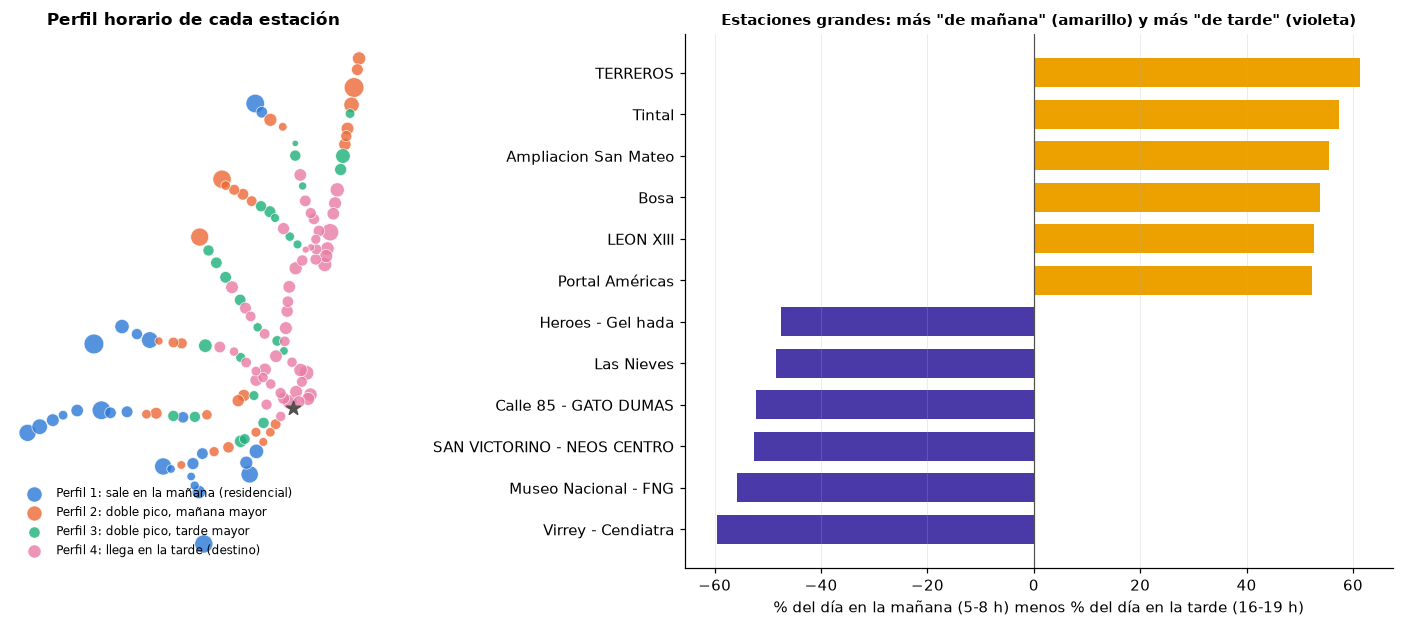

,nombre,val_dia,pct_manana,pct_tarde,perfil,km_centro
cod_estacion,,,,,,
07504,TERREROS,27673.6,66.5,5.1,1.0,13.7
05002,Tintal,19887.2,63.2,5.8,1.0,10.2
57503,Ampliacion San Mateo,17747.5,62.0,6.5,1.0,NaN
07010,Bosa,11362.9,62.7,9.0,1.0,11.7
07505,LEON XIII,12324.1,61.1,8.4,1.0,13.0
05000,Portal Américas,71392.6,58.8,6.6,1.0,11.3
02304,Heroes - Gel hada,17860.6,4.8,52.3,4.0,8.0
10007,Las Nieves,12164.0,4.4,52.8,4.0,0.9
02303,Calle 85 - GATO DUMAS,13778.4,4.7,56.9,4.0,8.4


In [18]:
# QUÉ HACE: ubica en el mapa los perfiles de estación y lista las estaciones más "residenciales" (casi toda la demanda en la mañana) y las más "de destino" (casi toda en la tarde).
# CÓMO: izquierda, mapa con el color del perfil (tamaño = demanda diaria); derecha, las estaciones con más de 10.000 validaciones por día ordenadas por la diferencia entre el % del día en la mañana y en la tarde.
# QUÉ MIRAR: si los perfiles de mañana quedan en la periferia y los de tarde en el centro y el norte; qué estaciones grandes casi no tienen validaciones en la tarde.
mp = est.dropna(subset=['perfil', 'lat']).copy()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={'width_ratios': [1, 1.15]})
for k, c in CP.items():
    s = mp[mp['perfil'] == k]; a1.scatter(s['lon'], s['lat'], s=np.sqrt(s['val_dia']) / 1.6, color=c, alpha=0.8, edgecolors='white', linewidths=0.5, label=f"Perfil {k}: {PERFIL[k]}")
a1.scatter(-74.0760, 4.5981, marker='*', s=90, color='#52514e', zorder=5); a1.legend(loc='lower left', fontsize=8)
a1.set_xticks([]); a1.set_yticks([]); a1.grid(False); a1.set_aspect('equal', adjustable='box'); a1.set_title('Perfil horario de cada estación')
for s_ in a1.spines.values(): s_.set_visible(False)
gr = est.loc[act]; gr = gr[gr['val_dia'] >= 10000].copy(); gr['diferencia'] = gr['pct_manana'] - gr['pct_tarde']
gr = pd.concat([gr.nsmallest(6, 'diferencia'), gr.nlargest(6, 'diferencia')]).sort_values('diferencia')
a2.barh([n[:28] for n in gr['nombre']], gr['diferencia'], color=[FR['tarde'] if v < 0 else FR['mañana'] for v in gr['diferencia']], height=0.7)
a2.axvline(0, color='#52514e', lw=0.8); a2.set_xlabel('% del día en la mañana (5-8 h) menos % del día en la tarde (16-19 h)')
a2.set_title('Estaciones grandes: más "de mañana" (amarillo) y más "de tarde" (violeta)', fontsize=10); a2.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig(FIGS / '04_mapa_perfiles_residencial.png', bbox_inches='tight'); plt.show()
gr.sort_values('diferencia', ascending=False)[['nombre', 'val_dia', 'pct_manana', 'pct_tarde', 'perfil', 'km_centro']].round(1)

### Lectura del paso 3

El K-Means separa las estaciones en cuatro formas de día:

| Perfil | Estaciones | % de las validaciones | % del día en 5-8 h | % del día en 16-19 h | Ejemplos |
|---|---|---|---|---|---|
| 1. Sale en la mañana (residencial) | 29 | 33 | 59 | 9 | Portal Américas, Suba, Sur |
| 2. Doble pico, mañana mayor | 32 | 22 | 43 | 21 | Portal Norte, Calle 80, El Dorado |
| 3. Doble pico, tarde mayor | 27 | 11 | 23 | 36 | Alcalá, Pradera, Temporal Marly |
| 4. Llega en la tarde (destino) | 56 | 32 | 9 | 51 | Calle 100, Temporal Flores, San Victorino |

- **Relación con el ranking:** de las 10 primeras estaciones del ranking, 9 son de perfil 1 o 2 (pico de la mañana) y una (Calle 100) es de perfil 4. La presión mayor se origina donde la gente sale de casa.
- Sí existen **estaciones donde casi todo se valida en la mañana y casi nada en la tarde**: Terreros (67 % del día en la mañana y 5 % en la tarde), Tintal (63 % y 6 %), Ampliación San Mateo (62 % y 7 %), Bosa (63 % y 9 %), León XIII (61 % y 8 %) y Portal Américas (59 % y 7 %). Son estaciones de la periferia (mediana de 9 km al centro) donde el viaje empieza.
- En el otro extremo están las estaciones **de destino**: Virrey (4 % y 64 %), Museo Nacional (4 % y 60 %), Calle 85 (5 % y 57 %), San Victorino (2 % y 55 %), Las Nieves y Héroes. Quedan en el centro y el norte (mediana de 5 km al centro).
- La alimentación se concentra en el perfil 1 (19 % de sus validaciones frente a 1 % en el perfil 4): son los portales.
- **Cautela:** el carácter "residencial" es una interpretación del horario de entrada; los datos no traen el uso del suelo. Además, solo se registran **entradas**: lo que ocurre en la salida de las estaciones de destino no se observa.
- **Para el personal:** el perfil indica **en qué franja** conviene el refuerzo (mañana en el perfil 1, tarde en el perfil 4, ambas en los perfiles 2 y 3).

## 4. Estaciones piloto: una por punta

El modelo (notebook 05) y el dimensionamiento del apoyo se desarrollan primero en **dos estaciones piloto, una por punta**, para cubrir la mañana y la tarde con el mismo método y después extenderlo a las demás. Criterios: (a) estar en el top 10 por demanda de su punta; (b) estar entre las de mayor presión respecto al espacio (m² o accesos); (c) datos completos en los 14 días y sin cambio de régimen; (d) pico estable, para poder anticiparlo.

In [19]:
# QUÉ HACE: presenta las dos estaciones piloto (San Mateo en la mañana y Calle 100 en la tarde) con los criterios que las justifican, frente a otras estaciones críticas de su punta.
# CÓMO: la tabla compara cada piloto con dos alternativas de su punta en demanda, espacio, acceso principal y estabilidad del pico; la estabilidad es el coeficiente de variación de las validaciones de su hora crítica en los 14 días.
# QUÉ MIRAR: que cada piloto sea top 10 por demanda y esté entre las de mayor presión respecto al espacio; que su pico sea estable (variación baja); las alternativas (Terreros en la mañana, sin m² Portal Américas; El Dorado y Portal Norte en la tarde).
PILOTOS = {'07503': 'mañana', '02300': 'tarde'}
def cv_pico(c, h):
    v = cubo.loc[c].xs(h, level='hora').values.astype(float); return v.std(ddof=1) / v.mean() * 100
filas = []
for k, t in tablas.items():
    for c in ([p for p, f_ in PILOTOS.items() if f_ == k] + (['07504', '05000'] if k == 'mañana' else ['06000', '02000'])):
        r = t.loc[c]
        filas.append({'punta': k, 'estación': r['estación'], 'piloto': 'sí' if c in PILOTOS else '', 'puesto por demanda': r['puesto por demanda'], 'hora crítica': int(r['hora crítica']), 'pico': r['pico'],
                      'm²': r['m²'], 'pico por m²': r['pico por m²'], 'accesos activos': r['accesos activos'], '% acceso principal': r['% acceso principal'], 'variación del pico (%)': cv_pico(c, int(r['hora crítica']))})
cand = pd.DataFrame(filas)
print("Estaciones piloto: San Mateo - C.C. Unisur (código 07503, punta de la mañana) y Calle 100 - Marketmedios (código 02300, punta de la tarde)")
cand.round(1)

Estaciones piloto: San Mateo - C.C. Unisur (código 07503, punta de la mañana) y Calle 100 - Marketmedios (código 02300, punta de la tarde)


,punta,estación,piloto,puesto por demanda,hora crítica,pico,m²,pico por m²,accesos activos,% acceso principal,variación del pico (%)
0,mañana,SAN MATEO - C.C. UNISUR,sí,8,6,7451.5,492.8,15.1,2,66.7,2.3
1,mañana,TERREROS,,12,6,6658.7,358.0,18.6,2,58.1,2.3
2,mañana,Portal Américas,,1,6,14411.6,NaN,NaN,3,41.2,4.6
3,tarde,Calle 100 - Marketmedios,sí,1,17,7646.9,814.4,9.4,2,54.9,9.2
4,tarde,Portal El Dorado - C.C. NUES,,3,17,5445.7,NaN,NaN,4,45.4,6.2
5,tarde,Portal Norte - Unicervantes,,2,17,5179.2,NaN,NaN,4,28.3,5.4


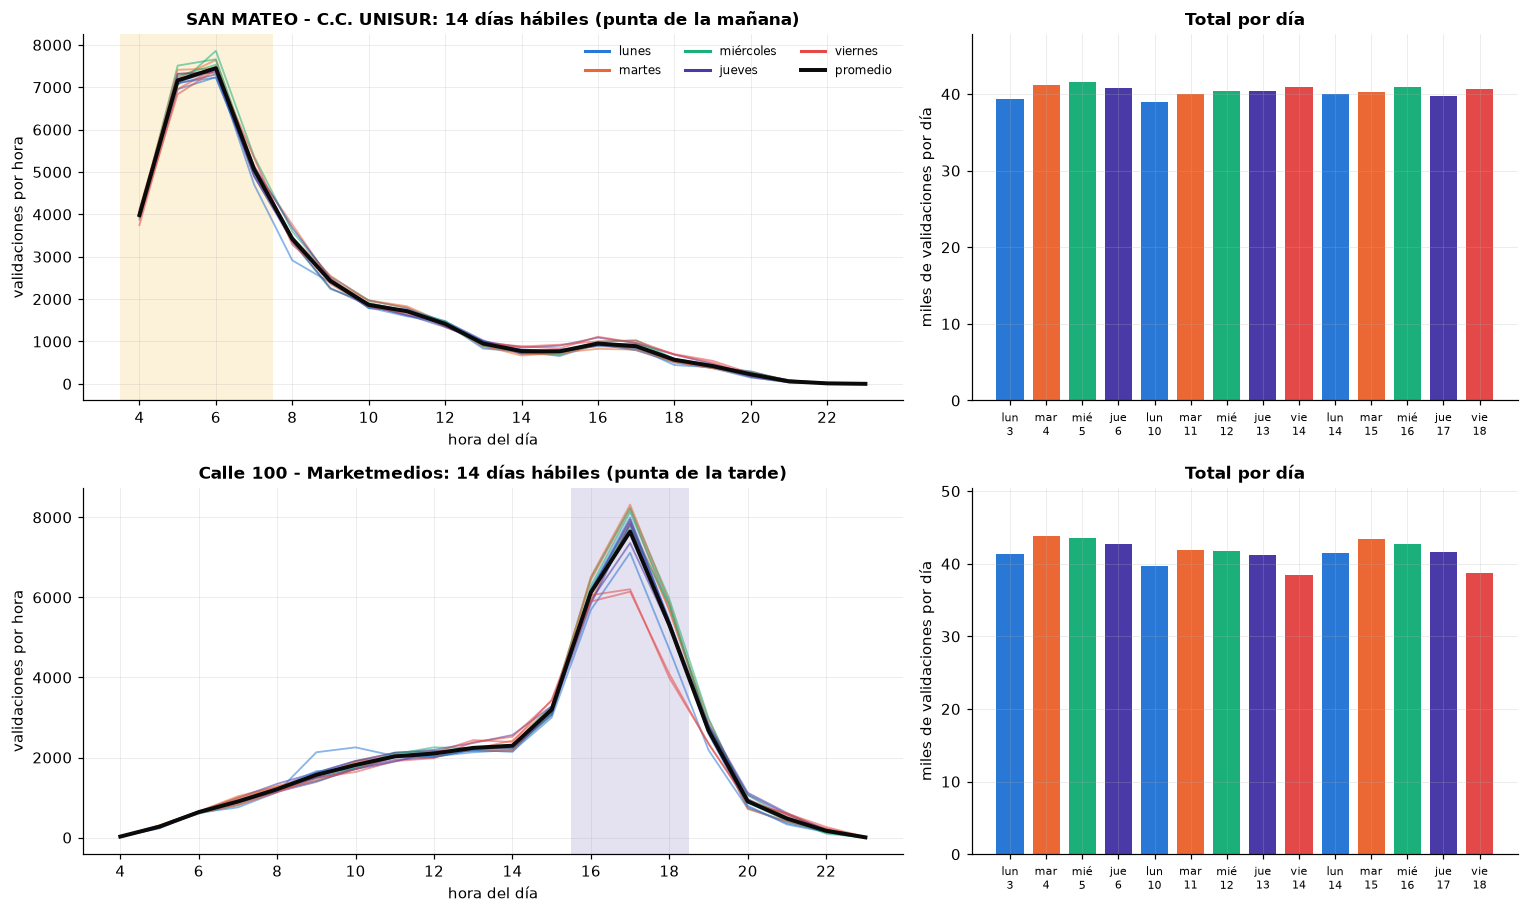

,lunes,martes,miércoles,jueves,viernes,promedio diario
estación,,,,,,
SAN MATEO - C.C. UNISUR,-2.3 %,+0.3 %,+1.5 %,-0.1 %,+1.1 %,40.366
Calle 100 - Marketmedios,-1.8 %,+3.5 %,+2.6 %,+0.6 %,-7.2 %,41.609


In [20]:
# QUÉ HACE: muestra el comportamiento de la semana en las dos estaciones piloto: la curva por hora de cada día hábil y el total diario.
# CÓMO: una fila por piloto; izquierda, una línea por día hábil (color por día de la semana) con el promedio en trazo grueso y sombreada la ventana crítica; derecha, total de validaciones de cada día hábil.
# QUÉ MIRAR: las curvas casi se superponen (poca variación entre días); en Calle 100 hay más dispersión entre días; el pico de San Mateo es a las 6 h y el de Calle 100, a las 17 h.
CD = {0: '#2a78d6', 1: '#eb6834', 2: '#1baf7a', 3: '#4a3aa7', 4: '#e34948'}
NOM = {0: 'lunes', 1: 'martes', 2: 'miércoles', 3: 'jueves', 4: 'viernes'}
fig, axes = plt.subplots(2, 2, figsize=(14, 8.4), gridspec_kw={'width_ratios': [1.5, 1]})
for fila_ax, (c, k) in zip(axes, PILOTOS.items()):
    s_ = cubo.loc[c].unstack('hora'); s_.index = pd.to_datetime(s_.index); a1, a2 = fila_ax
    umb = max(UMBRAL, 0.5 * s_.mean().max()); hv = [h for h in range(4, 24) if s_.mean()[h] >= umb]
    a1.axvspan(min(hv) - 0.5, max(hv) + 0.5, color=FR[k], alpha=0.15, lw=0)
    for fecha, fila in s_.iterrows(): a1.plot(range(4, 24), fila.loc[4:23], color=CD[fecha.dayofweek], alpha=0.55, lw=1.2)
    a1.plot(range(4, 24), s_.mean().loc[4:23], color='#0b0b0b', lw=2.6)
    a1.set_xticks(range(4, 24, 2)); a1.set_xlabel('hora del día'); a1.set_ylabel('validaciones por hora'); a1.set_title(f"{est.loc[c, 'nombre'][:28]}: 14 días hábiles (punta de la {k})")
    if c == '07503':
        a1.legend([plt.Line2D([0], [0], color=col, lw=2) for col in CD.values()] + [plt.Line2D([0], [0], color='#0b0b0b', lw=2.6)], list(NOM.values()) + ['promedio'], ncol=3, fontsize=8, loc='upper right')
    tot_d = s_.sum(axis=1)
    a2.bar(range(len(tot_d)), tot_d / 1e3, color=[CD[d.dayofweek] for d in tot_d.index], width=0.75)
    a2.set_xticks(range(len(tot_d))); a2.set_xticklabels([f"{NOM[d.dayofweek][:3]}\n{d.day}" for d in tot_d.index], fontsize=7.5)
    a2.set_ylabel('miles de validaciones por día'); a2.set_title('Total por día'); a2.set_ylim(0, tot_d.max() / 1e3 * 1.15)
plt.tight_layout(); plt.savefig(FIGS / '04_pilotos_semana.png', bbox_inches='tight'); plt.show()
filas = []
for c in PILOTOS:
    s_ = cubo.loc[c].unstack('hora'); s_.index = pd.to_datetime(s_.index); t_ = s_.sum(axis=1); p_ = t_.groupby(t_.index.dayofweek).mean()
    filas.append({'estación': est.loc[c, 'nombre'][:28], **{NOM[d]: f"{(p_[d] / t_.mean() - 1) * 100:+.1f} %" for d in p_.index}, 'promedio diario': f"{t_.mean():,.0f}".replace(',', '.')})
pd.DataFrame(filas).set_index('estación')

In [21]:
# QUÉ HACE: sugiere, para cada piloto y cada hora de su ventana crítica dentro de su punta, cuántas personas de apoyo se necesitarían bajo tres supuestos de capacidad, y cómo repartirlas entre los accesos en la hora del pico.
# CÓMO: personas = validaciones por hora / capacidad de una persona, redondeado hacia arriba; la capacidad (validaciones por hora que una persona puede ordenar) es un SUPUESTO sin respaldo en los datos y debe calibrarse con la operación (se prueban 1.000, 1.500 y 2.000); el reparto entre accesos usa lo observado en la hora del pico.
# QUÉ MIRAR: cuántas horas dura el refuerzo, cuántas personas hacen falta en la hora del pico según el supuesto, y cómo se reparten por acceso (un acceso dominante concentra más personas).
CAPS = [1000, 1500, 2000]
PUNTAS_P = {'mañana': (5, 8), 'tarde': (16, 19)}                     # la ventana se mide dentro de la punta, como en el plan del paso 5 y en el flujo de Prefect
for c, k in PILOTOS.items():
    serie = por_est_hora.loc[c, PUNTAS_P[k][0]:PUNTAS_P[k][1]]; h0 = int(serie.idxmax()); umb = max(UMBRAL, 0.5 * serie.max()); horas = [h for h, v in serie.items() if v >= umb]
    t = pd.DataFrame({'validaciones por hora': serie[horas].round(0)}); t.index = [f"{h}:00-{h + 1}:00" for h in horas]
    for cap in CAPS: t[f"personas (1 por cada {cap:,})".replace(',', '.')] = np.ceil(serie[horas].values / cap).astype(int)
    print(f"{est.loc[c, 'nombre']} - ventana crítica de la punta de la {k}: {horas[0]}:00 a {horas[-1] + 1}:00 ({len(horas)} horas)")
    display(t)
    todos = acc[(acc['cod_estacion'] == c) & (acc['hora'] == h0)]; a = todos.sort_values('validaciones', ascending=False); a = a[a['validaciones'] / todos['validaciones'].sum() >= 0.05]          # solo accesos con 5 % o más de la hora
    ta = pd.DataFrame({'acceso': a['Acceso_Estacion'].str[:34].values, 'validaciones en la hora del pico': a['validaciones'].round(0).values, '% de la hora': (a['validaciones'] / todos['validaciones'].sum() * 100).round(1).values})
    for cap in CAPS: ta[f"personas ({cap:,})".replace(',', '.')] = np.ceil(a['validaciones'].values / cap).astype(int)
    print(f"Reparto por acceso en la hora del pico ({h0}:00):"); display(ta)

SAN MATEO - C.C. UNISUR - ventana crítica de la punta de la mañana: 5:00 a 8:00 (3 horas)


,validaciones por hora,personas (1 por cada 1.000),personas (1 por cada 1.500),personas (1 por cada 2.000)
5:00-6:00,7162.0,8,5,4
6:00-7:00,7452.0,8,5,4
7:00-8:00,5065.0,6,4,3


Reparto por acceso en la hora del pico (6:00):


,acceso,validaciones en la hora del pico,% de la hora,personas (1.000),personas (1.500),personas (2.000)
0,(01) Acceso Peatonal Sur,4967.0,66.7,5,4,3
1,(03) Acceso Peatonal Norte,2482.0,33.3,3,2,2


Calle 100 - Marketmedios - ventana crítica de la punta de la tarde: 16:00 a 19:00 (3 horas)


,validaciones por hora,personas (1 por cada 1.000),personas (1 por cada 1.500),personas (1 por cada 2.000)
16:00-17:00,6126.0,7,5,4
17:00-18:00,7647.0,8,6,4
18:00-19:00,5314.0,6,4,3


Reparto por acceso en la hora del pico (17:00):


,acceso,validaciones en la hora del pico,% de la hora,personas (1.000),personas (1.500),personas (2.000)
0,(01) Acceso Norte,4196.0,54.9,5,3,3
1,(02) Acceso Sur,3445.0,45.1,4,3,2


## 5. Personal de apoyo: núcleo fijo y refuerzo variable

Hasta aquí se sabe **dónde** y **cuándo** hay presión. Falta decir **cuántas personas** y **con qué vinculación**. La demanda alta se concentra en dos ventanas cortas, una en la mañana y otra en la tarde, y dentro de cada ventana sube y baja. Por eso se separan dos tipos de personal:

- **Núcleo fijo:** las personas que se necesitan durante **toda la ventana**, es decir, el mínimo de personas que hace falta en cada hora de la ventana. Son personal de planta con un horario de unas horas en la mañana y otras en la tarde (turno partido) cuando la estación tiene las dos ventanas.
- **Refuerzo variable:** las personas que se necesitan solo en las horas más cargadas, por encima del núcleo. Se pagan solo por esas horas y se llaman según la demanda.

**Ejemplo.** Si se necesitan 3 personas de 4 a 7 y 2 personas de 7 a 8, el núcleo es de 2 personas durante toda la ventana (4 a 8) y la tercera es variable: ayuda de 4 a 7.

**¿Qué pasa cuando la necesidad baja de 3 personas a 2?** La tercera persona es del refuerzo variable: sale o pasa a otra estación que la necesite y esa hora no se paga. El núcleo fijo no cambia.

**Cómo se calcula**

1. **Ventana** de cada punta (mañana 5 a 8 h, tarde 16 a 19 h): las horas con al menos el 50 % del pico de la estación en esa punta, y con 1.000 validaciones por hora o más. Si la ventana dura menos de 2 horas, no se pide apoyo en esa punta. La ventana se mide dentro de cada punta, como en el flujo de Prefect y en la tabla de AWS; por eso puede ser más corta que la del paso 2, que usa el 50 % del pico del día (por ejemplo, San Mateo: 5:00-8:00 aquí y 4:00-8:00 en el paso 2).
2. **Personas por hora** = validaciones por hora / capacidad por persona, hacia arriba.
3. **Núcleo** = el mínimo de personas por hora dentro de la ventana. **Variable** = lo que excede el núcleo en cada hora.
4. Si la estación tiene ventana de mañana y de tarde, las personas del núcleo pueden cubrir las dos (turno partido). El número de personas fijas es el mayor de los dos núcleos.
5. Se revisa que ninguna persona fija pase de **42 horas por semana** (Ley 2101 de 2021; verificar con talento humano).

**Parámetros (supuestos a validar con la operación)**

| Parámetro | Valor | Nota |
|---|---|---|
| Capacidad por persona | 1.500 validaciones por hora | Escenario; se prueban 1.000 y 2.000 |
| Umbral de alta presión | 1.000 validaciones por hora | El mismo del ranking |
| Ventana | 50 % del pico de la estación | Como en el ranking |
| Duración mínima de la ventana | 2 horas | Una sola hora sobre el umbral no justifica un puesto |
| Días por semana | 5 | Solo días hábiles |
| Tope semanal por persona | 42 horas | Ley 2101 de 2021 |

**Lo que no está en los datos:** los costos, el ausentismo, los descansos y el tipo de contrato posible (tiempo parcial o por horas).

**En esta sección se comparan tres propuestas:** **A**, núcleo por ventana en la misma estación (esta parte); **B**, núcleo compartido entre estaciones (5.1); y **C**, turnos continuos de 8 y 4 horas (5.2), la más realista y la recomendada.


In [22]:
# QUÉ HACE: para cada estación calcula las personas que se necesitan en cada hora de sus ventanas y las separa en núcleo fijo (presentes toda la ventana) y refuerzo variable (el exceso en las horas más cargadas).
# CÓMO: ventana = horas de la punta con al menos 50 % del pico (y 1.000 o más), de 2 horas como mínimo; personas por hora = validaciones / 1.500, hacia arriba; núcleo = mínimo de la ventana; variable = suma de lo que excede el núcleo; si hay ventana de mañana y de tarde, las personas del núcleo pueden hacer turno partido.
# QUÉ MIRAR: cuántas personas fijas por estación, cuántas persona-horas de refuerzo, y cuántas horas por semana trabajaría una persona fija (el tope es 42).
CAP_PERSONA, DIAS_SEM, TOPE_SEMANAL, MIN_VENTANA_H = 1500, 5, 42, 2
PUNTAS = {'mañana': (5, 8), 'tarde': (16, 19)}

def plan_punta(serie, a, z, cap=CAP_PERSONA):
    s = serie.loc[a:z]; pico = s.max()
    if pico < UMBRAL: return None
    horas = [h for h, v in s.items() if v >= max(UMBRAL, 0.5 * pico)]                           # ventana de la punta
    if len(horas) < MIN_VENTANA_H: return None                                                  # una sola hora sobre el umbral no justifica un puesto
    n = np.ceil(s[horas].values / cap).astype(int)                                              # personas necesarias en cada hora de la ventana
    return {'horas': horas, 'n': n, 'nucleo': int(n.min()), 'variable': int((n - n.min()).sum()), 'persona_horas': int(n.sum())}

def plan_estacion(serie, cap=CAP_PERSONA):
    p = {k: plan_punta(serie, a, z, cap) for k, (a, z) in PUNTAS.items()}
    nm, nt = (p['mañana'] or {}).get('nucleo', 0), (p['tarde'] or {}).get('nucleo', 0)
    hm, ht = len((p['mañana'] or {}).get('horas', [])), len((p['tarde'] or {}).get('horas', []))
    h_sem = DIAS_SEM * (hm + ht if min(nm, nt) > 0 else max(hm if nm else 0, ht if nt else 0))     # horas por semana de la persona fija que más trabaja
    return {'puntas': p, 'nucleo_m': nm, 'nucleo_t': nt, 'horas_m': hm, 'horas_t': ht, 'fijos': max(nm, nt), 'turno_partido': min(nm, nt), 'h_sem_max': h_sem,
            'variable': sum((x or {}).get('variable', 0) for x in p.values()), 'persona_horas': sum((x or {}).get('persona_horas', 0) for x in p.values()),
            'ph_nucleo': nm * hm + nt * ht}

cand = [c for c in act if por_est_hora.loc[c].max() >= UMBRAL]                                  # estaciones de los rankings con alguna hora en alta presión
plan = {c: plan_estacion(por_est_hora.loc[c]) for c in cand}
plan = {c: p for c, p in plan.items() if p['persona_horas'] > 0}
per = pd.DataFrame({c: {k: v for k, v in p.items() if k != 'puntas'} for c, p in plan.items()}).T
per.insert(0, 'estación', [est.loc[c, 'nombre'].split(' - ')[0][:26] for c in per.index])
vent = lambda p, k: (f"{p['puntas'][k]['horas'][0]}:00-{p['puntas'][k]['horas'][-1] + 1}:00" if p['puntas'][k] else '-')
per['ventana mañana'] = [vent(plan[c], 'mañana') for c in per.index]; per['ventana tarde'] = [vent(plan[c], 'tarde') for c in per.index]
per = per.sort_values('persona_horas', ascending=False)
vista = per.head(15).rename(columns={'nucleo_m': 'núcleo mañana', 'nucleo_t': 'núcleo tarde', 'fijos': 'personas fijas', 'turno_partido': 'con turno partido', 'variable': 'persona-horas variables al día', 'h_sem_max': 'máx. horas por semana de una fija'})
print(f"{len(per)} estaciones con ventana de apoyo. Las 15 con más persona-horas:")
display(vista[['estación', 'ventana mañana', 'ventana tarde', 'núcleo mañana', 'núcleo tarde', 'personas fijas', 'con turno partido', 'persona-horas variables al día', 'máx. horas por semana de una fija']].set_index('estación'))
ph, nuc, var = int(per['persona_horas'].sum()), int(per['ph_nucleo'].sum()), int(per['variable'].sum())
horas_personas = []                                                                             # horas por semana de cada persona fija
for c, p in plan.items():
    horas_personas += [DIAS_SEM * (p['horas_m'] + p['horas_t'])] * p['turno_partido']
    horas_personas += [DIAS_SEM * p['horas_m']] * max(p['nucleo_m'] - p['turno_partido'], 0) + [DIAS_SEM * p['horas_t']] * max(p['nucleo_t'] - p['turno_partido'], 0)
hp = np.array(horas_personas)
print(f"Total de las {len(per)} estaciones: {ph} persona-horas por día en las ventanas = {nuc} del núcleo fijo ({nuc / ph * 100:.0f} %) + {var} del refuerzo variable ({var / ph * 100:.0f} %).")
print(f"Personas fijas: {int(per['fijos'].sum())}, de las cuales {int(per['turno_partido'].sum())} con turno partido. Horas por semana de una persona fija: promedio {hp.mean():.0f}, máximo {hp.max()} (tope {TOPE_SEMANAL}); ninguna pasa el tope: {bool((hp <= TOPE_SEMANAL).all())}.")
print(f"En equivalentes de jornada completa de {TOPE_SEMANAL} h por semana: {nuc * DIAS_SEM / TOPE_SEMANAL:.0f} del núcleo fijo + {var * DIAS_SEM / TOPE_SEMANAL:.0f} del refuerzo variable = {ph * DIAS_SEM / TOPE_SEMANAL:.0f}.")


79 estaciones con ventana de apoyo. Las 15 con más persona-horas:


,ventana mañana,ventana tarde,núcleo mañana,núcleo tarde,personas fijas,con turno partido,persona-horas variables al día,máx. horas por semana de una fija
estación,,,,,,,,
Portal Norte,6:00-9:00,16:00-19:00,5,3,5,3,6,30
Portal Américas,5:00-8:00,16:00-18:00,7,1,7,1,6,25
Portal Suba,5:00-8:00,16:00-19:00,5,1,5,1,7,30
Portal El Dorado,6:00-9:00,16:00-19:00,3,3,3,3,5,30
Portal Sur JFK Coop. Finan,5:00-8:00,16:00-18:00,5,1,5,1,5,25
Cabecera Calle 80,6:00-9:00,16:00-19:00,4,2,4,2,4,30
Cabecera Usme,5:00-8:00,16:00-18:00,5,1,5,1,3,25
Portal 20 de Julio,5:00-8:00,16:00-18:00,5,1,5,1,1,25
Banderas P. Central,5:00-9:00,16:00-18:00,3,1,3,1,3,30


Total de las 79 estaciones: 610 persona-horas por día en las ventanas = 494 del núcleo fijo (81 %) + 116 del refuerzo variable (19 %).
Personas fijas: 152, de las cuales 20 con turno partido. Horas por semana de una persona fija: promedio 16, máximo 35 (tope 42); ninguna pasa el tope: True.
En equivalentes de jornada completa de 42 h por semana: 59 del núcleo fijo + 14 del refuerzo variable = 73.


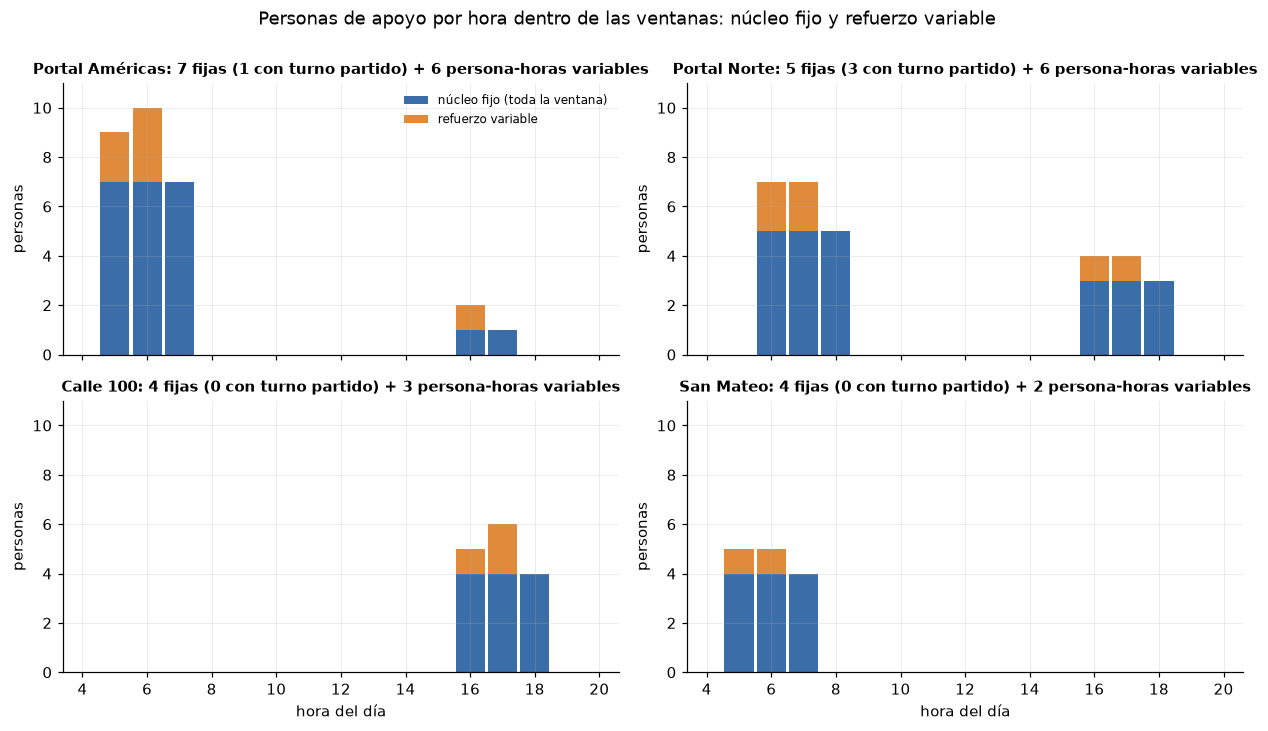

In [23]:
# QUÉ HACE: dibuja, para cuatro estaciones, las personas que se necesitan en cada hora de sus ventanas y separa el núcleo fijo del refuerzo variable.
# CÓMO: barras por hora dentro de cada ventana (capacidad de 1.500 por persona); el núcleo (azul) es el mínimo de la ventana; lo que excede es refuerzo variable (naranja).
# QUÉ MIRAR: el núcleo es una franja pareja en toda la ventana y el refuerzo aparece solo en las horas más cargadas; Calle 100 y San Mateo tienen una sola ventana; Portal Norte tiene dos.
CASOS = {'Portal Américas': '05000', 'Portal Norte': '02000', 'Calle 100': '02300', 'San Mateo': '07503'}
fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.6), sharex=True)
for ax, (nombre_c, c) in zip(axes.ravel(), CASOS.items()):
    p = plan[c]
    for k, x in p['puntas'].items():
        if not x: continue
        hs = np.array(x['horas']); nuc = np.full(len(hs), x['nucleo']); ref = x['n'] - nuc
        ax.bar(hs, nuc, width=0.9, color='#3b6ea8', label='núcleo fijo (toda la ventana)' if k == 'mañana' or not p['puntas']['mañana'] else None)
        ax.bar(hs, ref, width=0.9, bottom=nuc, color='#e08a3c', label='refuerzo variable' if k == 'mañana' or not p['puntas']['mañana'] else None)
    ax.set_title(f"{nombre_c}: {p['fijos']} fijas ({p['turno_partido']} con turno partido) + {p['variable']} persona-horas variables", fontsize=9.5)
    ax.set_xticks(range(4, 21, 2)); ax.set_xlim(3.4, 20.6); ax.set_ylim(0, 11); ax.set_ylabel('personas')
for ax in axes[1]: ax.set_xlabel('hora del día')
axes[0, 0].legend(loc='upper right', fontsize=8)
fig.suptitle('Personas de apoyo por hora dentro de las ventanas: núcleo fijo y refuerzo variable', y=1.0)
plt.tight_layout(); plt.savefig(FIGS / '04_personal_fijo_variable.png', bbox_inches='tight'); plt.show()


In [24]:
# QUÉ HACE: prueba cuánto cambian las cifras con la capacidad por persona y muestra una alternativa: que el núcleo cubra también las horas de menor demanda del día (en vez de solo las ventanas).
# CÓMO: se repite el cálculo con capacidades de 1.000, 1.500 y 2.000; la alternativa define el puesto k (la k-ésima persona) y lo cubre con jornadas de 8 horas si se necesita 6 horas al día o más, y con horas variables si menos.
# QUÉ MIRAR: la parte del trabajo que cubre el núcleo casi no cambia con la capacidad; la alternativa tiene más personas fijas con más horas por semana (se acerca más a 42) pero necesita suponer que cubren también las horas bajas.
filas = {}
for cap in [1000, 1500, 2000]:
    q = {c: plan_estacion(por_est_hora.loc[c], cap) for c in cand}; q = {c: v for c, v in q.items() if v['persona_horas'] > 0}
    f_, v_, p_, n_ = sum(x['fijos'] for x in q.values()), sum(x['variable'] for x in q.values()), sum(x['persona_horas'] for x in q.values()), sum(x['ph_nucleo'] for x in q.values())
    filas[f"1 por cada {cap:,}".replace(',', '.')] = {'estaciones con ventana': len(q), 'persona-horas por día': p_, 'personas fijas': f_, 'persona-horas variables': v_, '% del trabajo que cubre el núcleo fijo': round(n_ / p_ * 100, 1)}
print('Sensibilidad a la capacidad por persona (núcleo = toda la ventana):')
display(pd.DataFrame(filas).T)

def esquema_dia(serie, cap=CAP_PERSONA, jornada=8, h_min=6):
    n = np.where(serie.values >= UMBRAL, np.ceil(serie.values / cap), 0).astype(int)
    H = np.array([(n >= k).sum() for k in range(1, n.max() + 1)], dtype=int); r = H % jornada; extra = r >= h_min
    return int((H // jornada).sum() + extra.sum()), int(r[~extra].sum()), int(n.sum())
alt = np.array([esquema_dia(por_est_hora.loc[c]) for c in cand])
print(f"Alternativa (el núcleo cubre también el valle; puestos de 6 horas o más al día con jornadas de 8 horas): {alt[:, 0].sum()} personas fijas y {alt[:, 1].sum()} horas variables por día para {alt[:, 2].sum()} persona-horas, "
      f"frente a {int(per['fijos'].sum())} personas fijas y {var} persona-horas variables con el núcleo por ventana.")


Sensibilidad a la capacidad por persona (núcleo = toda la ventana):


,estaciones con ventana,persona-horas por día,personas fijas,persona-horas variables,% del trabajo que cubre el núcleo fijo
1 por cada 1.000,79.0,873.0,226.0,142.0,83.7
1 por cada 1.500,79.0,610.0,152.0,116.0,81.0
1 por cada 2.000,79.0,476.0,119.0,92.0,80.7


Alternativa (el núcleo cubre también el valle; puestos de 6 horas o más al día con jornadas de 8 horas): 60 personas fijas y 496 horas variables por día para 939 persona-horas, frente a 152 personas fijas y 116 persona-horas variables con el núcleo por ventana.


### 5.1 Compartir el núcleo entre estaciones

En el esquema anterior cada persona fija se queda en su estación y trabaja pocas horas por semana, porque la presión dura pocas horas. Pero la mañana y la tarde se necesitan en estaciones distintas (portales en la mañana; estaciones del centro y del norte en la tarde). Una misma persona puede cubrir **la ventana de la mañana en una estación y la de la tarde en otra**: completa más horas y se necesitan menos personas fijas. Los puestos que no tienen pareja (por ejemplo, hay más puestos de mañana que de tarde) pasan al **refuerzo variable**.

**Cómo se hace**

1. Cada puesto del núcleo es una ventana de una estación: el núcleo de la mañana de una estación son *n* puestos de mañana; el de la tarde, *m* puestos de tarde.
2. Se emparejan puestos de mañana con puestos de tarde de forma que la distancia total entre las dos estaciones de cada pareja sea la menor posible (asignación óptima; distancia en línea recta entre estaciones; si una estación no tiene coordenadas se supone 40 km, para emparejarla al final).
3. Una pareja es una persona fija con turno partido en dos estaciones. Se revisa que no pase de 42 horas por semana.
4. Los puestos sin pareja pasan al refuerzo variable.

**Lo que no está en los datos:** el tiempo real de traslado entre estaciones, que las personas acepten cambiar de estación y las reglas laborales del turno partido.


In [25]:
# QUÉ HACE: reparte el núcleo fijo entre estaciones: una misma persona cubre la ventana de la mañana de una estación y la de la tarde de otra, para completar horas con menos personas.
# CÓMO: cada puesto del núcleo es una ventana de una estación (mañana o tarde); se emparejan puestos de mañana con puestos de tarde minimizando la distancia entre las dos estaciones (asignación óptima); los puestos sin pareja pasan a refuerzo variable.
# QUÉ MIRAR: cuántas personas fijas quedan, cuántas horas por semana trabaja cada una (tope 42), cuántas persona-horas pasan a variable y qué distancia hay entre las dos estaciones de cada persona.
from scipy.optimize import linear_sum_assignment
puestos_m = [(c, plan[c]['horas_m']) for c in plan for _ in range(plan[c]['nucleo_m'])]       # un elemento por puesto de mañana: (estación, horas de la ventana)
puestos_t = [(c, plan[c]['horas_t']) for c in plan for _ in range(plan[c]['nucleo_t'])]

def km(c1, c2):
    la1, lo1, la2, lo2 = map(np.radians, [est.loc[c1, 'lat'], est.loc[c1, 'lon'], est.loc[c2, 'lat'], est.loc[c2, 'lon']])
    d = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))
    return 40.0 if np.isnan(d) else float(d)                                                  # sin coordenadas: distancia grande, se empareja al final

costo = np.array([[km(a[0], b[0]) for b in puestos_t] for a in puestos_m])
fi, co = linear_sum_assignment(costo)                                                         # empareja min(mañana, tarde) puestos con la menor distancia total
nom = lambda c: est.loc[c, 'nombre'].split(' - ')[0][:24]
pares = pd.DataFrame({'estación de la mañana': [nom(puestos_m[i][0]) for i in fi], 'estación de la tarde': [nom(puestos_t[j][0]) for j in co],
                      'km entre estaciones': costo[fi, co].round(1), 'horas por semana': [DIAS_SEM * (puestos_m[i][1] + puestos_t[j][1]) for i, j in zip(fi, co)]})
sin_m = [p for i, p in enumerate(puestos_m) if i not in set(fi)]; sin_t = [p for j, p in enumerate(puestos_t) if j not in set(co)]
h_sin = sum(h for _, h in sin_m) + sum(h for _, h in sin_t)                                   # persona-horas por día de puestos sin pareja
ph_pares = int(sum(puestos_m[i][1] + puestos_t[j][1] for i, j in zip(fi, co)))
var_comp = var + h_sin
print(f"Puestos del núcleo: {len(puestos_m)} de mañana y {len(puestos_t)} de tarde. Se forman {len(pares)} parejas (personas fijas con turno partido en dos estaciones); quedan {len(sin_m)} puestos de mañana y {len(sin_t)} de tarde sin pareja ({h_sin} persona-horas por día pasan a variable).")
conocidas = pares[pares['km entre estaciones'] < 40]                                          # parejas con coordenadas en las dos estaciones (40 km es el valor supuesto cuando faltan)
print(f"Distancia entre las dos estaciones de cada persona (parejas con coordenadas): mediana {conocidas['km entre estaciones'].median():.1f} km, máximo {conocidas['km entre estaciones'].max():.1f} km; "
      f"{(pares['km entre estaciones'] < 0.05).sum()} parejas son de la misma estación y {len(pares) - len(conocidas)} tienen una estación sin coordenadas.")
print(f"Horas por semana de una persona fija: promedio {pares['horas por semana'].mean():.1f}, máximo {pares['horas por semana'].max()} (tope {TOPE_SEMANAL}); ninguna pasa el tope: {bool((pares['horas por semana'] <= TOPE_SEMANAL).all())}.")
comp2 = pd.DataFrame({
    'núcleo en la misma estación': {'personas fijas': int(per['fijos'].sum()), 'horas por semana por persona fija (promedio)': round(float(hp.mean()), 1), 'persona-horas variables por día': var,
                                    '% del trabajo que cubren las fijas': round(int(per['ph_nucleo'].sum()) / ph * 100, 1)},
    'núcleo compartido entre estaciones': {'personas fijas': len(pares), 'horas por semana por persona fija (promedio)': round(float(pares['horas por semana'].mean()), 1), 'persona-horas variables por día': var_comp,
                                           '% del trabajo que cubren las fijas': round(ph_pares / ph * 100, 1)}}).T
display(comp2)
print('Ejemplos de parejas con dos estaciones distintas (las de más horas por semana):')
display(conocidas[conocidas['km entre estaciones'] >= 0.05].sort_values(['horas por semana', 'km entre estaciones'], ascending=[False, True]).drop_duplicates().head(8).reset_index(drop=True))


Puestos del núcleo: 91 de mañana y 81 de tarde. Se forman 81 parejas (personas fijas con turno partido en dos estaciones); quedan 10 puestos de mañana y 0 de tarde sin pareja (29 persona-horas por día pasan a variable).
Distancia entre las dos estaciones de cada persona (parejas con coordenadas): mediana 5.6 km, máximo 13.4 km; 19 parejas son de la misma estación y 10 tienen una estación sin coordenadas.
Horas por semana de una persona fija: promedio 28.7, máximo 35 (tope 42); ninguna pasa el tope: True.


,personas fijas,horas por semana por persona fija (promedio),persona-horas variables por día,% del trabajo que cubren las fijas
núcleo en la misma estación,152.0,16.2,116.0,81.0
núcleo compartido entre estaciones,81.0,28.7,145.0,76.2


Ejemplos de parejas con dos estaciones distintas (las de más horas por semana):


,estación de la mañana,estación de la tarde,km entre estaciones,horas por semana
0,Av. Primero de Mayo,SAN VICTORINO,3.2,35
1,Country Sur,Las Nieves,4.7,35
2,SUBA,NIZA,3.4,30
3,Mazurén,Calle 127,3.4,30
4,Cabecera Calle 80,Avenida 68,4.3,30
5,Portal 20 de Julio,Museo del Oro,4.8,30
6,Portal 20 de Julio,Las Aguas,5.2,30
7,Portal 20 de Julio,Universidades – CityU,5.4,30


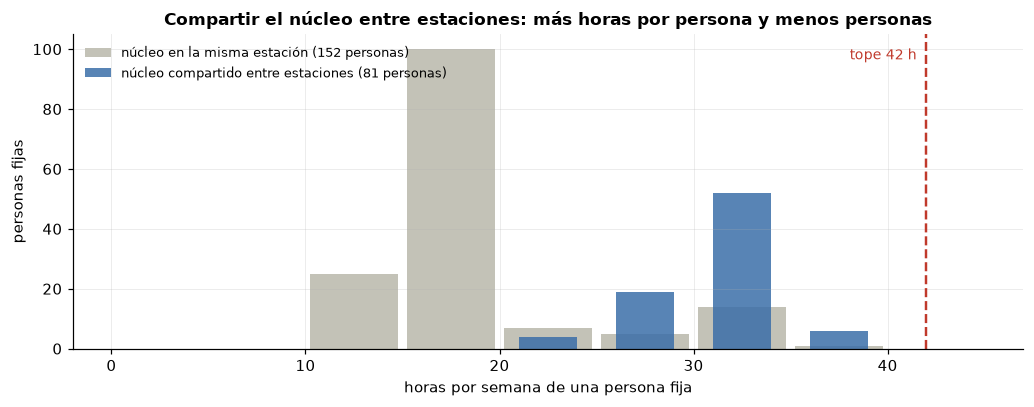

In [26]:
# QUÉ HACE: compara las horas por semana de una persona fija con el núcleo en la misma estación y con el núcleo compartido entre estaciones.
# CÓMO: histograma de las horas por semana de cada persona fija en los dos esquemas; la línea roja es el tope de 42 horas.
# QUÉ MIRAR: compartir entre estaciones mueve a las personas fijas hacia más horas por semana, aunque quedan por debajo del tope.
fig, ax = plt.subplots(figsize=(9.5, 3.8))
bins = np.arange(0, 46, 5)
ax.hist(hp, bins=bins, color='#c3c2b7', label=f"núcleo en la misma estación ({len(hp)} personas)", rwidth=0.9)
ax.hist(pares['horas por semana'], bins=bins, color='#3b6ea8', alpha=0.85, label=f"núcleo compartido entre estaciones ({len(pares)} personas)", rwidth=0.6)
ax.axvline(TOPE_SEMANAL, color='#c0392b', lw=1.6, ls='--'); ax.text(TOPE_SEMANAL - 0.5, ax.get_ylim()[1] * 0.92, 'tope 42 h', color='#c0392b', ha='right', fontsize=9)
ax.set_xlabel('horas por semana de una persona fija'); ax.set_ylabel('personas fijas'); ax.set_title('Compartir el núcleo entre estaciones: más horas por persona y menos personas'); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.savefig(FIGS / '04_personal_compartido.png', bbox_inches='tight'); plt.show()


### 5.2 Propuesta con turnos continuos (más realista)

Las dos propuestas anteriores cubren solo las **ventanas** y necesitan contratos que son difíciles de armar: personas de tiempo parcial (15 a 29 horas por semana) o turnos partidos con una pausa de 7 horas y cambio de estación. Esta propuesta parte de lo que se puede **contratar y programar**:

1. **Necesidad por hora de todo el día**, no solo de las ventanas: personas = validaciones por hora / 1.500, hacia arriba, en las horas con 1.000 o más. Las estaciones grandes no pasan de golpe de 10 personas a cero.
2. **Dos tipos de turno, siempre continuos:**
   - **Fijo:** 8 horas seguidas, tiempo completo (8 h x 5 días = 40 h por semana, dentro del tope de 42; los descansos van dentro del turno).
   - **Variable:** 4 horas seguidas, de medio tiempo, que se llama según la demanda.
3. **Programación por estación:** un programa entero decide cuántos turnos de cada tipo empiezan en cada hora para que en **cada hora haya al menos las personas necesarias** al menor costo. El costo es el de las horas pagadas; la hora variable cuesta más que la fija (33 %, supuesto; se prueban 0 %, 60 % y 100 %). Con ese costo, lo que se necesita muchas horas seguidas queda en turnos fijos y los picos cortos en turnos variables.
4. **Relevo:** se suma 10 % de personal fijo para cubrir ausentismo, vacaciones y descansos (supuesto; no está en los datos).
5. Solo **días hábiles**; los fines de semana son otro régimen.

| Parámetro | Valor | Nota |
|---|---|---|
| Turno fijo | 8 horas continuas | 40 h por semana |
| Turno variable | 4 horas continuas | Medio tiempo, por llamado |
| Recargo de la hora variable | 33 % | Supuesto; se prueban 0 %, 60 % y 100 % |
| Relevo por ausentismo y vacaciones | 10 % de las personas fijas | Supuesto |
| Capacidad por persona | 1.500 validaciones por hora | La misma de las propuestas anteriores |

**Lo que no está en los datos:** los costos reales, el ausentismo real, que las personas acepten turnos de 4 horas y las reglas laborales de los descansos.


In [27]:
# QUÉ HACE: arma, para cada estación, los turnos continuos que cubren las personas necesarias en cada hora con el menor costo: turnos fijos de 8 horas y turnos variables de 4 horas.
# CÓMO: personas necesarias por hora = validaciones / 1.500, hacia arriba, en las horas con 1.000 o más; por estación, un programa entero elige cuántos turnos de cada tipo empiezan en cada hora para cubrir la necesidad de cada hora con el menor costo en horas pagadas (la hora variable cuesta 33 % más).
# QUÉ MIRAR: cuántos turnos fijos y variables pide cada estación, qué parte de las horas pagadas se necesita de verdad (utilización) y cuántas personas fijas hacen falta con el relevo.
from scipy.optimize import milp, LinearConstraint, Bounds
PRIMA_VAR, RELEVO, H_FIJO, H_VAR = 0.33, 0.10, 8, 4

def turnos_continuos(n, prima=PRIMA_VAR):
    horas = [h for h in range(24) if n[h] > 0]
    sf = [s for s in range(0, 24 - H_FIJO + 1) if any(s <= h < s + H_FIJO for h in horas)]      # horas de inicio posibles del turno fijo
    sv = [s for s in range(0, 24 - H_VAR + 1) if any(s <= h < s + H_VAR for h in horas)]
    A = np.array([[1.0 if s <= h < s + H_FIJO else 0.0 for s in sf] + [1.0 if s <= h < s + H_VAR else 0.0 for s in sv] for h in horas])
    costo = np.array([H_FIJO] * len(sf) + [H_VAR * (1 + prima) + 0.01] * len(sv), dtype=float)       # el 0,01 desempata a favor del turno fijo cuando cuestan lo mismo
    r = milp(costo, constraints=LinearConstraint(A, lb=np.array([n[h] for h in horas], dtype=float), ub=np.inf), integrality=np.ones(len(costo)), bounds=Bounds(0, np.inf))
    assert r.success, 'el programa no encontró solución'
    x = np.round(r.x).astype(int)
    fijos = {s: int(v) for s, v in zip(sf, x[:len(sf)]) if v > 0}; vari = {s: int(v) for s, v in zip(sv, x[len(sf):]) if v > 0}
    en_f, en_v = np.zeros(24, int), np.zeros(24, int)
    for s, v in fijos.items(): en_f[s:s + H_FIJO] += v
    for s, v in vari.items(): en_v[s:s + H_VAR] += v
    return {'n': n, 'fijos': fijos, 'variables': vari, 'en_f': en_f, 'en_v': en_v}

def necesidad(serie, cap=CAP_PERSONA): return np.where(serie.values >= UMBRAL, np.ceil(serie.values / cap), 0).astype(int)
def resumen_turnos(t):
    nf, nv = sum(t['fijos'].values()), sum(t['variables'].values())
    return {'turnos_fijos': nf, 'turnos_variables': nv, 'horas_pagadas': nf * H_FIJO + nv * H_VAR, 'horas_necesarias': int(t['n'].sum()), 'personas_pico': int(t['n'].max())}

cand_t = [c for c in act if por_est_hora.loc[c].max() >= UMBRAL]
turnos = {c: turnos_continuos(necesidad(por_est_hora.loc[c])) for c in cand_t}
tt = pd.DataFrame({c: resumen_turnos(t) for c, t in turnos.items()}).T
tt.insert(0, 'estación', [est.loc[c, 'nombre'].split(' - ')[0][:26] for c in tt.index])
tt['utilización (%)'] = (tt['horas_necesarias'] / tt['horas_pagadas'] * 100).round(0)
tt = tt.sort_values('horas_necesarias', ascending=False)
print(f"{len(tt)} estaciones en alta presión. Las 15 con más horas necesarias:")
display(tt.head(15).rename(columns={'personas_pico': 'personas en el pico', 'turnos_fijos': 'turnos fijos (8 h)', 'turnos_variables': 'turnos variables (4 h)', 'horas_pagadas': 'horas pagadas al día',
                                    'horas_necesarias': 'horas necesarias al día'}).set_index('estación')[['personas en el pico', 'turnos fijos (8 h)', 'turnos variables (4 h)', 'horas pagadas al día', 'horas necesarias al día', 'utilización (%)']])
NF, NV = int(tt['turnos_fijos'].sum()), int(tt['turnos_variables'].sum()); HP, HN = int(tt['horas_pagadas'].sum()), int(tt['horas_necesarias'].sum())
PERSONAS_FIJAS = int(np.ceil(NF * (1 + RELEVO)))
print(f"Total: {NF} turnos fijos de 8 h + {NV} turnos variables de 4 h por día; {HP} horas pagadas para {HN} horas necesarias (utilización {HN / HP * 100:.0f} %).")
print(f"Personas fijas: {NF} en turno + {PERSONAS_FIJAS - NF} de relevo (10 %) = {PERSONAS_FIJAS}; cada una trabaja {H_FIJO * DIAS_SEM} h por semana (tope {TOPE_SEMANAL} h). Turnos variables por llamado: {NV} por día ({NV * H_VAR} horas).")


93 estaciones en alta presión. Las 15 con más horas necesarias:


,personas en el pico,turnos fijos (8 h),turnos variables (4 h),horas pagadas al día,horas necesarias al día,utilización (%)
estación,,,,,,
Portal Norte,7,4,7,60,55,92.0
Portal Américas,10,3,9,60,51,85.0
Portal Suba,8,2,8,48,44,92.0
Portal Sur JFK Coop. Finan,8,4,5,52,42,81.0
Cabecera Calle 80,6,4,4,48,41,85.0
Portal El Dorado,5,3,6,48,41,85.0
Cabecera Usme,7,2,6,40,37,92.0
Portal 20 de Julio,6,2,5,36,34,94.0
Calle 100,6,2,6,40,33,82.0


Total: 48 turnos fijos de 8 h + 219 turnos variables de 4 h por día; 1260 horas pagadas para 939 horas necesarias (utilización 75 %).
Personas fijas: 48 en turno + 5 de relevo (10 %) = 53; cada una trabaja 40 h por semana (tope 42 h). Turnos variables por llamado: 219 por día (876 horas).


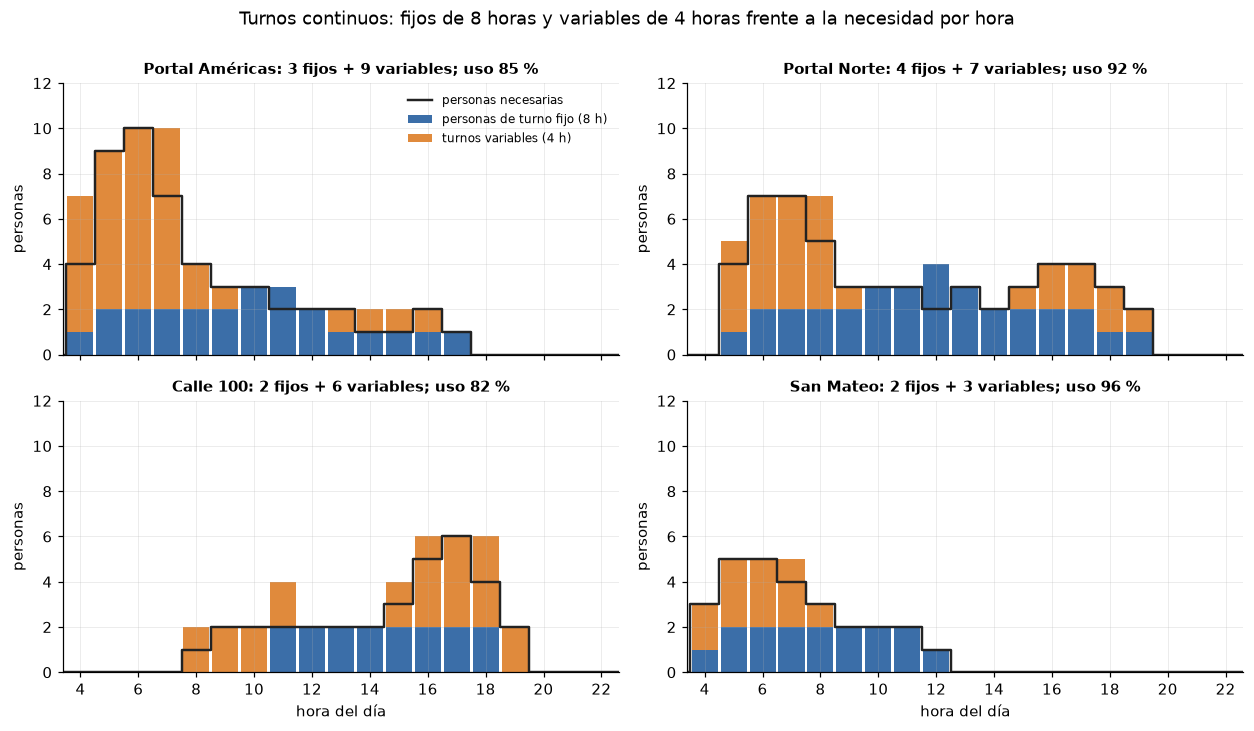

In [28]:
# QUÉ HACE: dibuja, para cuatro estaciones, cuántas personas hay de turno cada hora (fijas y variables) frente a las que se necesitan.
# CÓMO: barras azules = personas de turno fijo; naranja = turnos variables de 4 horas; la línea negra es la necesidad por hora (capacidad de 1.500 por persona); donde la barra supera la línea hay horas pagadas que no se necesitan.
# QUÉ MIRAR: los turnos fijos siguen la demanda sostenida y los variables aparecen solo en los picos; cuánta holgura queda al empezar y terminar cada turno.
CASOS = {'Portal Américas': '05000', 'Portal Norte': '02000', 'Calle 100': '02300', 'San Mateo': '07503'}
fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.6), sharex=True)
for ax, (nombre_c, c) in zip(axes.ravel(), CASOS.items()):
    t = turnos[c]; hs = np.arange(24); r = resumen_turnos(t)
    ax.bar(hs, t['en_f'], width=0.9, color='#3b6ea8', label='personas de turno fijo (8 h)')
    ax.bar(hs, t['en_v'], width=0.9, bottom=t['en_f'], color='#e08a3c', label='turnos variables (4 h)')
    ax.step(np.append(hs, 24) - 0.5, np.append(t['n'], t['n'][-1]), where='post', color='#222222', lw=1.6, label='personas necesarias')
    ax.set_title(f"{nombre_c}: {r['turnos_fijos']} fijos + {r['turnos_variables']} variables; uso {r['horas_necesarias'] / r['horas_pagadas'] * 100:.0f} %", fontsize=9.5)
    ax.set_xticks(range(0, 24, 2)); ax.set_xlim(3.4, 22.6); ax.set_ylim(0, 12); ax.set_ylabel('personas')
for ax in axes[1]: ax.set_xlabel('hora del día')
axes[0, 0].legend(loc='upper right', fontsize=8)
fig.suptitle('Turnos continuos: fijos de 8 horas y variables de 4 horas frente a la necesidad por hora', y=1.0)
plt.tight_layout(); plt.savefig(FIGS / '04_turnos_continuos.png', bbox_inches='tight'); plt.show()


In [29]:
# QUÉ HACE: compara las tres propuestas de personal en la misma tabla y prueba el supuesto del recargo de la hora variable.
# CÓMO: las dos primeras salen de las celdas anteriores (núcleo por ventana en la misma estación y compartido entre estaciones); la tercera, de los turnos continuos; la necesidad total del día es la suma de personas por hora con 1.000 o más.
# QUÉ MIRAR: qué parte de la necesidad del día cubre cada propuesta, qué contratos exige y cuántas personas fijas pide; cómo cambia la propuesta de turnos continuos con el recargo de la hora variable.
NECESIDAD_DIA = int(sum(int(necesidad(por_est_hora.loc[c]).sum()) for c in cand_t))
comp3 = pd.DataFrame({
    'A. núcleo por ventana (misma estación)': {'personas fijas': int(per['fijos'].sum()), 'horas por semana por persona fija': round(float(hp.mean()), 1), 'horas variables pagadas por día': var,
                                               'horas pagadas por día': ph, 'necesidad del día cubierta (%)': round(ph / NECESIDAD_DIA * 100), 'contrato que exige': 'tiempo parcial (turno partido en la misma estación)'},
    'B. núcleo compartido entre estaciones': {'personas fijas': len(pares), 'horas por semana por persona fija': round(float(pares['horas por semana'].mean()), 1), 'horas variables pagadas por día': var_comp,
                                              'horas pagadas por día': ph, 'necesidad del día cubierta (%)': round(ph / NECESIDAD_DIA * 100), 'contrato que exige': 'turno partido con pausa de 7 h y cambio de estación'},
    'C. turnos continuos (fijos 8 h + variables 4 h)': {'personas fijas': PERSONAS_FIJAS, 'horas por semana por persona fija': H_FIJO * DIAS_SEM, 'horas variables pagadas por día': NV * H_VAR,
                                                         'horas pagadas por día': HP, 'necesidad del día cubierta (%)': 100, 'contrato que exige': 'tiempo completo y medio tiempo por llamado'}}).T
comp3['horas pagadas por hora necesaria'] = (comp3['horas pagadas por día'] / (comp3['necesidad del día cubierta (%)'] / 100 * NECESIDAD_DIA)).round(2)
print(f"Necesidad total del día (horas con 1.000 validaciones por hora o más, {len(cand_t)} estaciones): {NECESIDAD_DIA} persona-horas. A y B cubren solo las ventanas ({ph}); C cubre todo el día.")
print('Las horas pagadas de A y B se suponen pagadas solo cuando se trabajan (contratos por horas o de tiempo parcial); las de C incluyen las horas de turno que no se necesitan.')
display(comp3)
filas = {}
for prima in [0.0, 0.33, 0.6, 1.0]:
    tp = {c: turnos_continuos(necesidad(por_est_hora.loc[c]), prima) for c in cand_t}
    nf_, nv_ = sum(sum(t['fijos'].values()) for t in tp.values()), sum(sum(t['variables'].values()) for t in tp.values())
    filas[f"hora variable {prima * 100:.0f} % más cara"] = {'turnos fijos': nf_, 'personas fijas con relevo': int(np.ceil(nf_ * (1 + RELEVO))), 'turnos variables (4 h)': nv_, 'horas pagadas': nf_ * H_FIJO + nv_ * H_VAR,
                                                            'utilización (%)': round(NECESIDAD_DIA / (nf_ * H_FIJO + nv_ * H_VAR) * 100, 1)}
print('Sensibilidad al recargo de la hora variable (turnos continuos):')
pd.DataFrame(filas).T


Necesidad total del día (horas con 1.000 validaciones por hora o más, 93 estaciones): 939 persona-horas. A y B cubren solo las ventanas (610); C cubre todo el día.
Las horas pagadas de A y B se suponen pagadas solo cuando se trabajan (contratos por horas o de tiempo parcial); las de C incluyen las horas de turno que no se necesitan.


,personas fijas,horas por semana por persona fija,horas variables pagadas por día,horas pagadas por día,necesidad del día cubierta (%),contrato que exige,horas pagadas por hora necesaria
A. núcleo por ventana (misma estación),152,16.2,116,610,65,tiempo parcial (turno partido en la misma estación),1.0
B. núcleo compartido entre estaciones,81,28.7,145,610,65,turno partido con pausa de 7 h y cambio de estación,1.0
C. turnos continuos (fijos 8 h + variables 4 h),53,40,876,1260,100,tiempo completo y medio tiempo por llamado,1.34


Sensibilidad al recargo de la hora variable (turnos continuos):


,turnos fijos,personas fijas con relevo,turnos variables (4 h),horas pagadas,utilización (%)
hora variable 0 % más cara,48.0,53.0,219.0,1260.0,74.5
hora variable 33 % más cara,48.0,53.0,219.0,1260.0,74.5
hora variable 60 % más cara,48.0,53.0,219.0,1260.0,74.5
hora variable 100 % más cara,267.0,294.0,0.0,2136.0,44.0


### Lectura del paso 5

**Qué se necesita (una persona por cada 1.500 validaciones por hora).** Las 93 estaciones en alta presión necesitan **939 persona-horas por día** (horas con 1.000 validaciones por hora o más). De ellas, **610 caen dentro de las ventanas** de la mañana y de la tarde (79 estaciones con ventana de al menos 2 horas) y 329 en las horas intermedias.

**Propuesta A: núcleo por ventana en la misma estación.** Las personas que se necesitan toda la ventana son el núcleo fijo (494 persona-horas, 81 % de las ventanas) y el exceso en las horas más cargadas es refuerzo variable (116). Son **152 personas fijas** que trabajan en promedio 16 horas por semana (máximo 35): casi todas de tiempo parcial. Ejemplos: Portal Norte, 5 fijas (3 con turno partido) y 6 persona-horas variables; Portal Américas, 7 fijas y 6; Calle 100, 4 fijas y 3 (solo ventana de tarde); San Mateo, 4 fijas y 2 (solo ventana de mañana).

**Propuesta B: núcleo compartido entre estaciones.** Hay 91 puestos de núcleo en la mañana y 81 en la tarde. Si una misma persona cubre la ventana de la mañana en una estación y la de la tarde en otra, bastan **81 personas fijas** de 28,7 horas por semana en promedio (máximo 35), con dos estaciones a una mediana de 5,6 km (máximo 13,4 km entre las parejas con coordenadas; 10 parejas incluyen una estación sin coordenadas). Los 10 puestos de mañana sin pareja pasan a variable (145 persona-horas variables en total). Exige turnos partidos con una pausa de unas 7 horas y cambiar de estación a mitad del día.

**Propuesta C: turnos continuos (más realista).** Cubre la necesidad de **todo el día**, no solo de las ventanas, con turnos que sí se pueden contratar: fijos de 8 horas seguidas (tiempo completo, 40 h por semana) y variables de 4 horas seguidas (medio tiempo, por llamado). Un programa entero por estación elige los turnos de menor costo que cubren cada hora. Resultado:

- **48 turnos fijos de 8 horas y 219 turnos variables de 4 horas por día**; con 10 % de relevo por ausentismo y vacaciones son **53 personas fijas** de 40 horas por semana (tope 42).
- Se pagan 1.260 horas por día para 939 horas necesarias: **utilización de 75 %**, es decir 1,34 horas pagadas por cada hora necesaria. El resto es la holgura de empezar y terminar turnos completos.
- Por estación: Portal Norte, 4 fijos y 7 variables (uso de 92 %); Portal Américas, 3 y 9 (85 %); Calle 100, 2 y 6 (82 %); San Mateo, 2 y 3 (96 %).
- **Sensibilidad al recargo de la hora variable:** con 0 %, 33 % o 60 % más cara sale la misma mezcla; con 100 % (un turno variable de 4 horas cuesta lo mismo que uno fijo de 8) todo pasa a fijo: 267 turnos, 294 personas, 2.136 horas pagadas y utilización de 44 %. La mezcla se sostiene mientras la hora variable cueste menos del doble que la fija.

**Comparación.** A y B cubren solo las ventanas (65 % de la necesidad del día) y suponen contratos de tiempo parcial o turnos partidos con cambio de estación. **C cubre el 100 %, usa contratos estándar (tiempo completo y medio tiempo) y cabe en el tope de 42 horas**, a cambio de pagar horas de turno que no se necesitan y de contar con una bolsa de personal variable que acepte unos 219 llamados de 4 horas por día. **Se recomienda C como propuesta base**; A y B quedan como alternativas si la operación logra contratar tiempo parcial o compartir personal entre estaciones.

**Cuando la necesidad baja de 3 a 2 personas,** la tercera ocupa un turno variable: sale (o pasa a otra estación) y esa hora no se paga. El núcleo fijo no cambia.

**Sensibilidad a la capacidad y alternativa.** Cambiar la capacidad por persona modifica el total (226, 152 o 119 personas fijas con 1.000, 1.500 o 2.000 en la propuesta A), pero el núcleo siempre cubre entre el 81 % y el 84 % del trabajo de las ventanas.


### Lectura del paso 4 y conclusiones

**Estaciones piloto: San Mateo (punta de la mañana) y Calle 100 (punta de la tarde).**

| | San Mateo - C.C. Unisur (07503) | Calle 100 - Marketmedios (02300) |
|---|---|---|
| Punta | mañana | tarde |
| Puesto por demanda en su punta | 8 | 1 |
| Pico | 7.452 validaciones por hora a las 6 h | 7.647 por hora a las 17 h |
| Área y densidad | 493 m²; 15,1 por hora por m² (puesto 3) | 814 m²; 9,4 por hora por m² (puesto 1) |
| Accesos | 2 activos; principal (peatonal sur) 67 % | 2 activos; norte 55 % y sur 45 % |
| Estabilidad del pico (variación entre días) | 2,3 % | 9,2 % |
| Efecto semanal | lunes -2,3 %, miércoles +1,5 % | martes +3,5 %, viernes -7,2 % |

- **Por qué estas dos:** son estaciones con flujo de portal en una fracción del espacio y con casi toda la demanda de la hora concentrada en uno o dos accesos; están entre las críticas por demanda y por presión respecto al espacio; y juntas cubren las dos puntas. San Mateo tiene el pico más estable de la lista; Calle 100 es menos estable, con los viernes claramente más bajos (el pico del viernes ronda 6.100 validaciones por hora frente a unas 8.000 los demás días).
- **Alternativas descartadas:** Terreros (más densa, 18,6 por m², pero 12.º por demanda) y Portal Américas (primero por demanda, sin m² en el archivo oficial).

**Apoyo sugerido (escenarios, no datos).** La capacidad de una persona de apoyo (validaciones por hora que puede ordenar) no está en los datos; se probaron 1.000, 1.500 y 2.000 y debe calibrarse con la operación.
- **San Mateo, 5:00 a 8:00 (3 horas):** en la hora del pico (7.452 por hora) se necesitarían **8, 5 o 4 personas** según el supuesto (1 por cada 1.000, 1.500 o 2.000); el acceso peatonal sur (67 %) concentraría 5, 4 o 3 y el norte (33 %), 3, 2 o 2.
- **Calle 100, 16:00 a 19:00 (3 horas):** en la hora del pico (7.647 por hora), **8, 6 o 4 personas**; acceso norte (55 %) 5, 3 o 3 y acceso sur (45 %) 4, 3 o 2.

**Personal de apoyo (paso 5).** Con una persona por cada 1.500 validaciones por hora (escenario), las 93 estaciones en alta presión necesitan 939 persona-horas por día; 610 caen dentro de las ventanas de la mañana y de la tarde. Se compararon tres propuestas: **A**, núcleo fijo por ventana en la misma estación (152 personas de unas 16 horas por semana); **B**, núcleo compartido entre estaciones (81 personas de 29 horas por semana, con turno partido y pausa de 7 horas); y **C**, **turnos continuos**: 48 turnos fijos de 8 horas y 219 turnos variables de 4 horas por día, con 53 personas fijas contando 10 % de relevo, que cubren toda la necesidad del día con una utilización de 75 %. A y B cubren solo las ventanas (65 %) y exigen contratos de tiempo parcial o turnos partidos; **C es la propuesta recomendada** porque usa contratos estándar y cabe en el tope de 42 horas. Cuando la necesidad baja, sale el personal variable; el núcleo no cambia.

**Qué aportó cada análisis al plan:** los **accesos** dicen *dónde dentro de la estación* ubicar a las personas y cuántas por acceso; los **m² y los accesos activos** dicen qué estaciones suben de prioridad por tener poco espacio (San Mateo, Calle 100, Virrey, Héroes) y justifican las pilotos; el **ranking por franja** dice *qué estaciones* y la **ventana crítica**, *a qué horas*; el **mapa y los perfiles** muestran en qué zonas de la ciudad ocurre cada punta (portales de la periferia en la mañana, centro y norte en la tarde).

**Variable objetivo del modelo:** `validaciones` por hora de cada estación; el notebook 05 construye los métodos de comparación y el modelo para las dos pilotos y después para todas las estaciones.

## Conclusiones

1. Se analizan solo los **14 días hábiles**: el sábado, el domingo y el festivo son otro régimen (30 a 62 % de un día hábil y otra curva).
2. La presión se concentra en **dos puntas** (5-8 h y 16-19 h) y en **pocas estaciones** (26 de 144 reúnen la mitad de la demanda).
3. La necesidad de refuerzo se midió con la **carga sobre el umbral** (intensidad y duración); el ranking es robusto frente al volumen y al umbral. Se calculó un **ranking por franja** para no dejar la tarde tapada por la mañana.
4. **Mañana:** portales y cabeceras de la periferia, con 8 a 14 mil validaciones por hora y ventana crítica de 5:00 a 8:00 o de 6:00 a 9:00. **Tarde:** Calle 100 (7,6 mil por hora), Portal Norte, El Dorado y estaciones céntricas, con ventana de 16:00 a 19:00.
5. La **presión respecto al espacio** (m² o accesos activos) casi no cambia el top de la mañana, pero sube a estaciones pequeñas de la tarde y confirma a San Mateo y Calle 100.
6. Dentro de la estación, el **acceso principal** recibe entre 26 % y 67 % de la hora crítica; en los portales casi dos tercios del día entra por alimentación; y el cuarto de hora más cargado supera a la hora entre 4 % y 19 %.
7. Hay cuatro **perfiles de estación**; 9 de las 10 primeras del ranking son de mañana.
8. El pico de las estaciones del ranking es **estable** (variación mediana de 4,6 %), lo que permite anticiparlo.
9. El personal de apoyo se cubre con **turnos continuos**: 53 personas fijas de tiempo completo (40 horas por semana) y 219 turnos variables de 4 horas por día para las 93 estaciones en alta presión. Las propuestas por ventana (152 personas de tiempo parcial, o 81 compartidas entre estaciones) cubren solo el 65 % de la necesidad del día.

**Limitaciones:** solo 14 días hábiles en tres semanas separadas; la necesidad de personal no está en los datos, el umbral de 1.000 validaciones por hora es provisional y la capacidad por persona es un supuesto, ambos a calibrar con la operación; solo se observan entradas; los m² no existen para los portales y cabeceras; 11 de 144 estaciones sin coordenadas. No hay costos ni tipo de contrato reales: los turnos continuos suponen un recargo de 33 % para la hora variable, 10 % de relevo y una bolsa de personal que acepte turnos de 4 horas por llamado (unos 219 por día); en las propuestas por ventana, el traslado entre estaciones se estimó en línea recta y 10 parejas incluyen una estación sin coordenadas.

**Siguiente paso:** notebook 05, con el modelo de predicción de las validaciones por estación y hora comparado contra métodos simples con validación temporal, aplicado a San Mateo y Calle 100 y luego a todas.